# Lab 03 — Exercise 2 — Fine-tuning & Binary Evaluation

**Môn học:** Deep Learning — UTH. **Bài toán:** phân tích cảm xúc và phân loại văn bản nhị phân với Hugging Face.

Notebook có hai chế độ. **`MODE="view"`** đọc kết quả Kaggle đã xác minh và tạo hoặc dùng lại run phân tích chứa hình/bảng; không tải dataset/model và không train. **`MODE="train"`** gọi cùng module với CLI để thực thi thí nghiệm mới. Output đã lưu trong notebook là một lượt chạy `view`, không phải một lần GPU training mới.

Mỗi trực quan hóa hiển thị bên dưới được đọc từ file ảnh trong `outputs/`; bảng có bản JSON nguồn tương ứng. Artifacts thí nghiệm cũ không bị ghi đè. Các bảng JSON phục vụ tái tính toán và kiểm tra, còn hình phục vụ diễn giải bài. Cài môi trường theo [README](../README.md) trước khi chạy và xem [description](../description_lab_03.md) cho các quyết định phạm vi.

## Roadmap — Exercise 2

| Phase | Mục tiêu / quyết định | Module / file tham chiếu | Đầu vào | Artifact / trực quan hóa |
|---|---|---|---|---|
| P01 — Data contract | Dùng đủ official train/validation/test | [loader.py](../src/datasets/loader.py): `load_data` | Rotten Tomatoes | Split sizes và `class_distribution.png` |
| P02 — EDA | Hiểu độ dài và phân bố nhãn trước khi diễn giải | [workflow.py](../src/workflow.py), [analysis.py](../src/analysis.py) | Dataset hoặc predictions đã lưu | `data_statistics.json`, `review_length_distribution.png` |
| P03 — Encoding | Truncation 128, padding theo batch | [loader.py](../src/datasets/loader.py): `tokenize_data` | Text, tokenizer | Tokenized datasets; `token_length_distribution.png` |
| P04 — Model | Backbone pretrained + đầu phân loại hai lớp | [classifier.py](../src/models/classifier.py): `load_model` | DistilBERT nền | Logits `(B,2)`, config và provenance |
| P05 — Sanity | Forward/loss/gradient có học được? | [trainer.py](../src/training/trainer.py), [test_training.py](../tests/test_training.py) | Batch nhỏ và model disposable | Kết quả test; không đổi model train chính |
| P06 — Optimization | Train ba epochs; chọn checkpoint bằng validation | [trainer.py](../src/training/trainer.py): `make_trainer` | Train/validation | `trainer_history.json`, `learning_curves.png` |
| P07 — Threshold | Chọn ngưỡng bằng validation rồi đóng băng | [thresholds.py](../src/training/thresholds.py) | Validation probabilities | `validation_threshold/threshold_curves.png`, `decision_threshold.json`, validation comparison |
| P08 — Test | Đánh giá một lần sau lựa chọn | [workflow.py](../src/workflow.py): `evaluate_model`, [metrics.py](../src/training/metrics.py) | Checkpoint/ngưỡng cố định, test | Metrics, confusion matrix, toàn bộ predictions |
| P09 — Curves | Phân biệt ranking, threshold và calibration | [analysis.py](../src/analysis.py) | Test probabilities đã lưu | ROC/PR, reliability và histogram xác suất |
| P10 — Error analysis | Đọc câu sai, confidence và loại lỗi | [analysis.py](../src/analysis.py), [workflow.py](../src/workflow.py): `choose_samples` | Predictions + nhãn thật | `sample_predictions.png`, bảng metric theo lớp |
| P11 — Save/load | Kiểm tra checkpoint và truy vết artifact | [classifier.py](../src/models/classifier.py): `verify_saved_model`, [runs.py](../src/utils/runs.py) | Model đã train | `best_model/`, `reload_check.json`, SHA256 manifest |
| P12 — Report | Kết luận đúng phạm vi bằng chứng | [walkthrough](../walkthrough_lab_03.md), [description](../description_lab_03.md) | Tất cả artifacts | Bảng quyết định, giới hạn và báo cáo thống nhất |

**Điểm tách bắt buộc:** train cập nhật trọng số; validation chọn checkpoint/ngưỡng; test đo chất lượng cuối. Việc vẽ đường cong trên test trong phần chẩn đoán không cho phép quay lại chọn ngưỡng tốt nhất từ test.

| Phase bổ sung | Module / file tham chiếu | Artifact đã lưu |
|---|---|---|
| Kiểm toán policy và provenance | [threshold_evidence.py](../src/threshold_evidence.py), [decision.py](../src/decision.py) | `threshold_audit.json`, checkpoint SHA256 và validation fingerprint |
| So sánh validation/test/inference | [threshold_analysis.py](../src/threshold_analysis.py) | `tables.json`, `test_comparison.png`, `confusion_comparison.png`, `changed_predictions.png` |
| Lưu toàn bộ cell output | [render_notebooks.py](../scripts/render_notebooks.py) | Run `notebook_render` chứa bản notebook đã thực thi |


In [1]:
from pathlib import Path
import sys
import json

LAB = next((p / "labs/lab03" if (p / "labs/lab03/src/workflow.py").is_file() else p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "labs/lab03/src/workflow.py").is_file() or (p / "src/workflow.py").is_file()), None)
if LAB is None:
    raise RuntimeError("Open this notebook inside the Lab-DL repository")
sys.path.insert(0, str(LAB.parents[1]))

import pandas as pd
from IPython.display import display, Image, Markdown
from labs.lab03.src.workflow import read_config, exercise1, finetune
from labs.lab03.src.evidence import selected_run, audit_exercise1, audit_finetuning, read_json
from labs.lab03.src.analysis import ensure_analysis, ensure_exercise1_analysis

# view: xem kết quả có sẵn; chỉ tạo/cache artifacts phân tích, không tải model hay train.
# train: tạo thí nghiệm mới; fine-tuning mặc định cần GPU CUDA.
MODE = "view"
assert MODE in {"view", "train"}
config = read_config()

def show_figure(path, caption):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing saved visualization: {path}")
    display(Markdown(f"**{caption}**"))
    display(Image(filename=str(path)))

print("Chế độ:", MODE)
print("Nguồn bài:", LAB)
print("Hình và bảng được đọc từ artifacts đã lưu trong outputs/.")
from labs.lab03.src.threshold_analysis import ensure_threshold_analysis

Chế độ: view
Nguồn bài: /workspace/Lab-DL/labs/lab03
Hình và bảng được đọc từ artifacts đã lưu trong outputs/.


## 2.1. Data contract và phân chia vai trò

`cornell-movie-review-data/rotten_tomatoes` được dùng đầy đủ: **8.530 train, 1.066 validation, 1.066 test**. Giữ split chính thức và không lấy subset. Mỗi review có đúng một nhãn: 0 Negative, 1 Positive.

Train là dữ liệu cập nhật trọng số. Validation được dùng trong chọn checkpoint, sau đó chọn threshold của checkpoint đã chọn. Test được giữ để đánh giá cuối. Không chọn lại hyperparameters hoặc ngưỡng dựa trên việc test tăng bao nhiêu.

Run lịch sử hiện có đã hoàn thành ba epochs với quyết định argmax. Nó chưa lưu validation probabilities, nên phần threshold-selection mới không được coi là đã thực hiện trên run đó.

In [2]:
finetuning_run = finetune(config) if MODE == "train" else selected_run("finetuning")
finetuning_audit = audit_finetuning(finetuning_run)
analysis_run = ensure_analysis(finetuning_run)
analysis_summary = read_json(analysis_run / "analysis_summary.json")
analysis_tables = read_json(analysis_run / "tables.json")
print("Run fine-tuning:", finetuning_run.name)
print("Run phân tích đã lưu:", analysis_run)
print("Số dự đoán test được đối chiếu:", finetuning_audit["correct"] + finetuning_audit["incorrect"])
threshold_analysis_run = ensure_threshold_analysis(finetuning_run)
threshold_tables = read_json(threshold_analysis_run / "tables.json") if threshold_analysis_run else None
threshold_summary = read_json(threshold_analysis_run / "summary.json") if threshold_analysis_run else None
if threshold_analysis_run:
    print("Run phân tích threshold và checkpoint reload:", threshold_analysis_run)


Run fine-tuning: 20261025T181550Z_finetuning_e02bced7
Run phân tích đã lưu: /workspace/Lab-DL/labs/lab03/outputs/runs/20261026T080403Z_analysis_7b9e92eb
Số dự đoán test được đối chiếu: 1066
Run phân tích threshold và checkpoint reload: /workspace/Lab-DL/labs/lab03/outputs/runs/20261026T124315Z_threshold_analysis_8bc30b27


## 2.2. EDA — số lượng, nhãn và độ dài review

Cần tách ba phạm vi thống kê. Kích thước train/validation/test có trong `data_statistics.json`. Toàn bộ nhãn và văn bản test có trong `all_predictions.json`, cho phép kiểm tra trực tiếp phân bố test và số từ review test. Độ dài token train là thống kê khác và có biểu đồ riêng.

Không gọi biểu đồ số từ test là độ dài token train: một từ có thể tách thành nhiều tokens. Không tự suy ra phân bố nhãn train/validation từ phân bố test khi run lịch sử chưa lưu các nhãn đó. EDA của lần chạy mới có thể mở rộng nhưng phải lưu phạm vi và nguồn dữ liệu rõ ràng.

,split,samples
0,train,8530
1,validation,1066
2,test,1066


**Phân bố nhãn của test đã lưu**

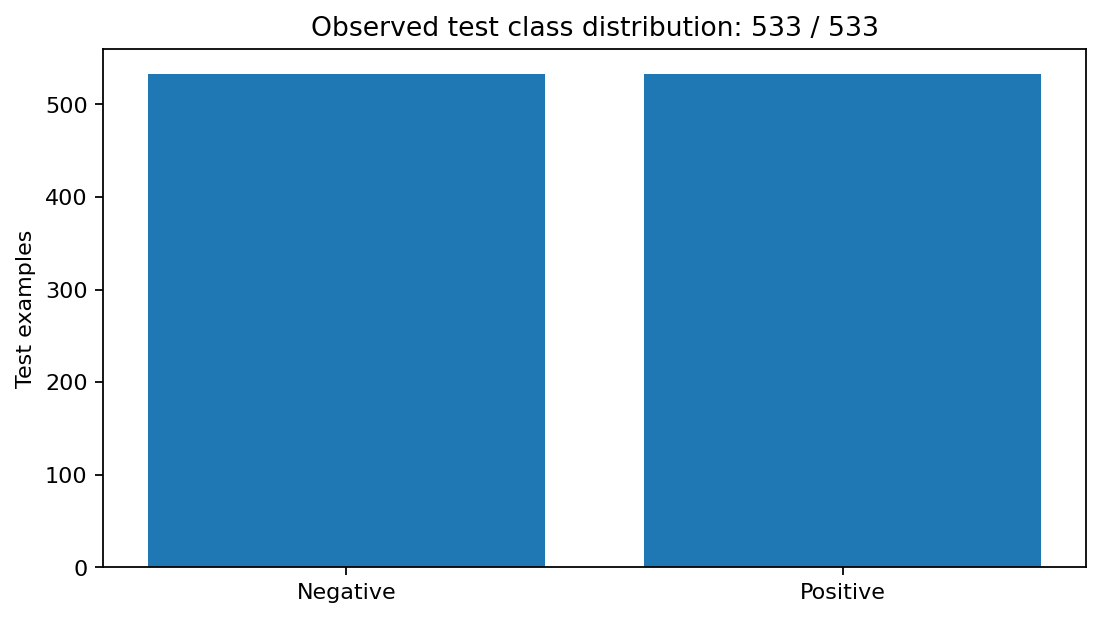

**Phân bố số từ review test, không phải token length train**

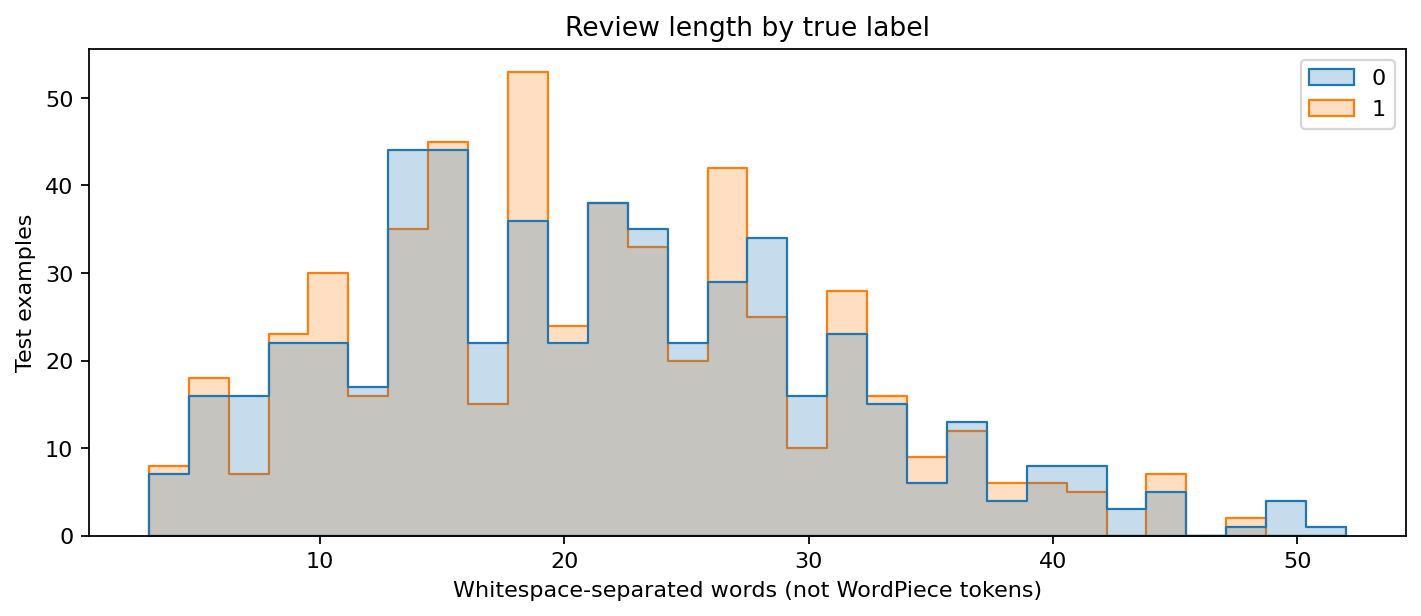

In [3]:
display(pd.DataFrame(analysis_tables["split_sizes"]))
show_figure(analysis_run / "class_distribution.png", "Phân bố nhãn của test đã lưu")
show_figure(analysis_run / "review_length_distribution.png", "Phân bố số từ review test, không phải token length train")

## 2.3. Tokenization, truncation và dynamic padding

`tokenize_data` gọi tokenizer theo batch, dùng truncation và max length 128. `DataCollatorWithPadding` thực hiện padding khi lấy batch; không cần lưu mọi mẫu đã đệm đến 128 trong dataset.

```python
tokenized = dataset.map(
    lambda batch: tokenizer(batch["text"], truncation=True, max_length=128),
    batched=True,
    remove_columns=["text"],
)
collator = DataCollatorWithPadding(tokenizer)
```

Run Kaggle tham chiếu ghi train trung bình 27,37 tokens, tối đa 78 và tỉ lệ truncation 0%. Kết luận không bị cắt áp dụng cho **train đã đo**, không tự suy rộng sang split chưa thống kê. Mask giúp bỏ qua token đệm; label được collator chuyển thành `labels` để model tính loss.

,mean,max,truncated_fraction
0,27.368347,78,0.0


**Token length train trước truncation và cutoff 128**

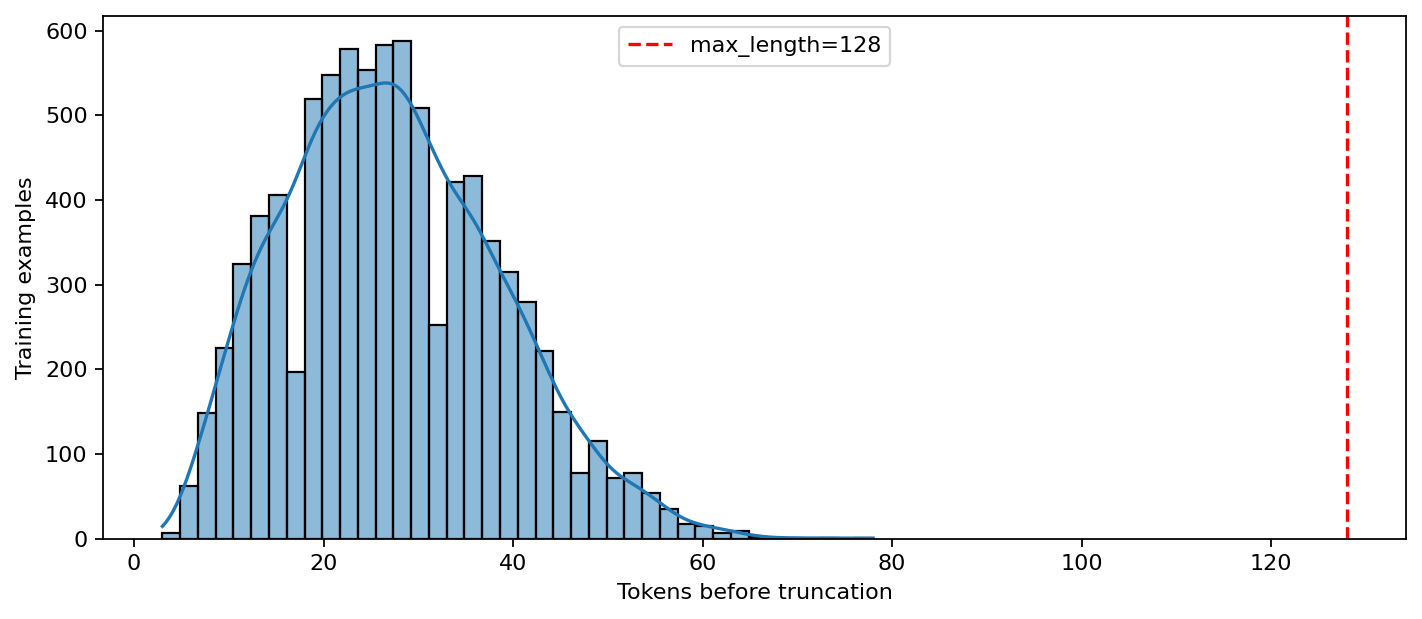

In [4]:
display(pd.DataFrame(analysis_tables["token_statistics"]))
show_figure(finetuning_run / "token_length_distribution.png", "Token length train trước truncation và cutoff 128")

## 2.4. Kiến trúc và hợp đồng tensor

Backbone DistilBERT dùng sáu transformer encoder layers, hidden size 768 và multi-head self-attention. `AutoModelForSequenceClassification` thêm pre-classifier, activation, dropout và classifier hai lớp. Đầu phân loại mới khởi tạo nên cảnh báo “weights newly initialized” khi tải backbone là bình thường.

| Giai đoạn | Tensor / cấu trúc | Ý nghĩa |
|---|---|---|
| Tokenizer/collator | `input_ids`, `attention_mask`: `(B,S)` | B review, S token sau padding |
| Labels | `(B,)`, số nguyên 0/1 | Một nhãn cho mỗi review |
| Backbone | Biểu diễn contextual theo token | Mỗi token phụ thuộc ngữ cảnh |
| Classification head | Logits `(B,2)` | Điểm số cho hai lớp |
| Loss | Scalar cross-entropy | Đại lượng tối ưu khi train |

Cross-entropy nhận **logits**, không cần softmax thủ công trước loss. Softmax dùng khi cần xác suất để vẽ ROC/PR, phân tích confidence hoặc áp threshold.

## 2.5. Sanity overfit và thiết kế training

Trước khi tốn tài nguyên cho job lớn, test ép học một batch nhỏ để xác nhận model/loss/gradient/optimizer có thể học. Bài test dùng mô hình disposable, không đem trọng số đã overfit vào fine-tuning chính.

Cấu hình hiện hành: AdamW, LR `2e-5`, weight decay `0.01`, warmup ratio `0.1`, ba epochs, batch train/eval 16/32. LR nhỏ hạn chế phá vỡ biểu diễn pretrained; warmup giúp ổn định các bước đầu. Đây là lựa chọn thực hành được chốt, không phải chứng minh tối ưu trên mọi dataset.

FP16 chỉ bật khi CUDA có sẵn; seed 42 hỗ trợ tái lập. Môi trường của run được lưu trong snapshot. Không khẳng định seed cho kết quả bit-identical trên mọi phiên bản/thiết bị.

In [5]:
display(pd.DataFrame(analysis_tables["training_config"]))
display(pd.DataFrame(analysis_tables["environment_versions"]))

,dataset_name,dataset_revision,model_name,model_revision,max_length,batch_size,eval_batch_size,learning_rate,num_train_epochs,weight_decay,warmup_ratio,fp16
0,cornell-movie-review-data/rotten_tomatoes,main,distilbert/distilbert-base-uncased,main,128,16,32,0.00002,3,0.01,0.1,True


,library,version
0,torch,2.6.0
1,transformers,4.48.3
2,datasets,3.2.0
3,evaluate,0.4.3
4,accelerate,1.3.0
5,numpy,2.2.2
6,scikit-learn,1.6.1


## 2.6. Trainer, lịch học và checkpoint selection

Trainer xử lý dataloader, forward/backward, gradient accumulation nếu cấu hình, optimizer, scheduler và evaluation. Với một GPU và batch 16, `ceil(8530/16)=534` optimizer steps mỗi epoch; ba epochs có 1.602 bước.

Cấu trúc khởi tạo tương ứng trong module (trích lược để giải thích):

```python
args = TrainingArguments(
    output_dir=str(run_path / "checkpoints"),
    learning_rate=2e-5,
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
)
trainer = Trainer(model=model, args=args,
                  train_dataset=ds["train"],
                  eval_dataset=ds["validation"],
                  data_collator=DataCollatorWithPadding(tokenizer))
trainer.train()
```

Mỗi epoch có validation và checkpoint. Tiêu chí định trước là `metric_for_best_model="accuracy"`, `load_best_model_at_end=True`. Không đổi sang chọn loss chỉ vì đã thấy kết quả test hoặc vì epoch khác có một metric trông đẹp hơn.

Bảng dưới tách loss trung bình trong quá trình tối ưu với loss đo khi model ở eval mode trên train. Dropout và thời điểm đo khác nhau khiến hai giá trị không nhất thiết bằng nhau.

,epoch,step,optimization_loss,train_eval_loss,train_accuracy,validation_loss,validation_accuracy
0,1.0,534,0.4609,0.293893,0.880774,0.403606,0.822702
1,2.0,1068,0.2597,0.126099,0.959789,0.378666,0.841463
2,3.0,1602,0.1515,0.093490,0.972098,0.489638,0.843340


**Learning curves: train/validation loss và accuracy**

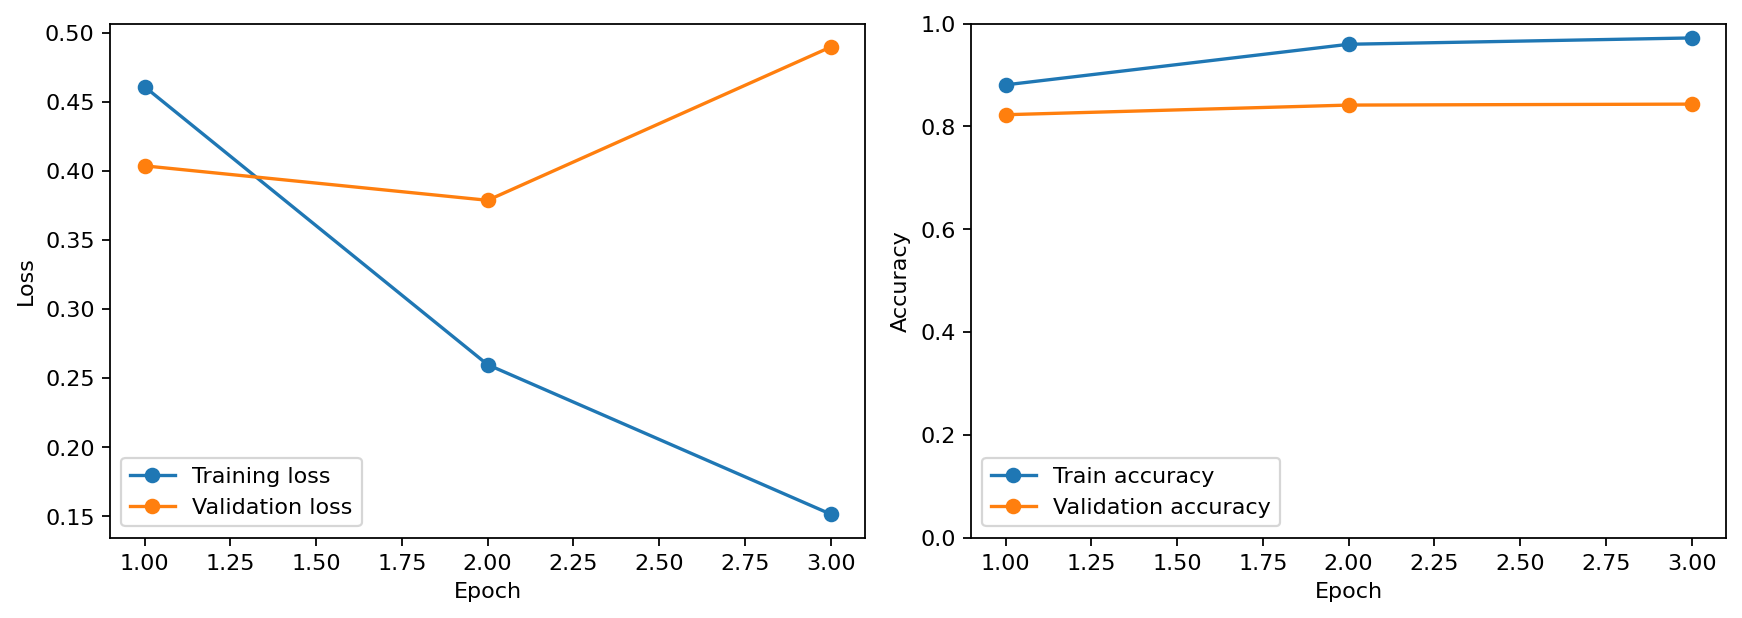

In [6]:
display(pd.DataFrame(analysis_tables["epoch_history"]))
show_figure(finetuning_run / "learning_curves.png", "Learning curves: train/validation loss và accuracy")

### Đọc đường học, không chỉ liệt kê ảnh

Ở run Kaggle tham chiếu, train accuracy tăng từ khoảng 88,08% lên 97,21%, trong khi validation tăng từ 82,27% lên 84,33%. Validation loss giảm ở epoch 2 nhưng tăng ở epoch 3. Đây là dấu hiệu overfitting, không phải bằng chứng cứ train thêm là test sẽ tốt hơn.

Epoch 3 được chọn theo validation accuracy; epoch 2 có validation loss thấp hơn. Chênh accuracy validation giữa hai epoch cuối chỉ tương ứng hai mẫu. Báo cáo giữ nguyên tiêu chí selection và ghi rõ giới hạn của một seed.

## 2.7. Quét threshold cho binary classification

Argmax trên hai xác suất tương đương ngưỡng 0,5 khi không có tie. Trong nhánh threshold dùng quy ước **Positive nếu $p_1\geq t$**; ở đúng tie, quy ước này khác argmax chọn index nhỏ nhất.

Giảm ngưỡng thường tăng recall và số False Positives; tăng ngưỡng thường giảm False Positives nhưng có thể bỏ sót thêm Positive. Không có một ngưỡng “tốt nhất” độc lập mục tiêu.

Quy trình mới: lấy probabilities trên **validation của checkpoint đã chọn**, quét grid định trước, chọn Macro F1 cao nhất, tie-break gần 0,5 rồi ngưỡng nhỏ hơn, lưu `decision_threshold.json`, sau đó cố định ngưỡng để đánh giá test. Không đưa nhãn test vào hàm chọn threshold.

```python
selection = select_validation_threshold(
    validation_labels, validation_positive_probabilities,
    split="validation",
)
frozen_threshold = selection["selected_threshold"]
test_predictions = (test_positive_probabilities >= frozen_threshold).astype(int)
```

Đoạn minh họa dùng hai tập đầu vào tách biệt. Hàm selection từ chối `split="test"`; việc tái dùng test labels dưới tên validation vẫn là lỗi phương pháp mà kiểm tra string không tự phát hiện được. Vì vậy cả code guard lẫn provenance/split contract đều cần thiết.

**Kết quả đã thực thi:** run `20261026T083558Z_threshold_selection_b64cf564` dùng đủ 1.066 mẫu validation của checkpoint cũ, quét 19 ngưỡng từ 0,05 đến 0,95, chọn **0,8** theo Macro F1. Validation Macro F1 tăng từ **0,843279** ở 0,5 lên **0,852663** ở 0,8. Đây là bước hậu xử lý trên checkpoint đã phục hồi, không phải train lại.


,method,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,Reference threshold 0.5,0.5,0.84334,0.830325,0.863039,0.82364,0.17636,0.846366,0.843279,439,94,73,460,533,533,1066
1,Selected threshold 0.8,0.8,0.85272,0.867188,0.833021,0.87242,0.12758,0.849761,0.852663,465,68,89,444,533,533,1066


**Quét 19 threshold trên validation; policy được đóng băng tại 0,8**

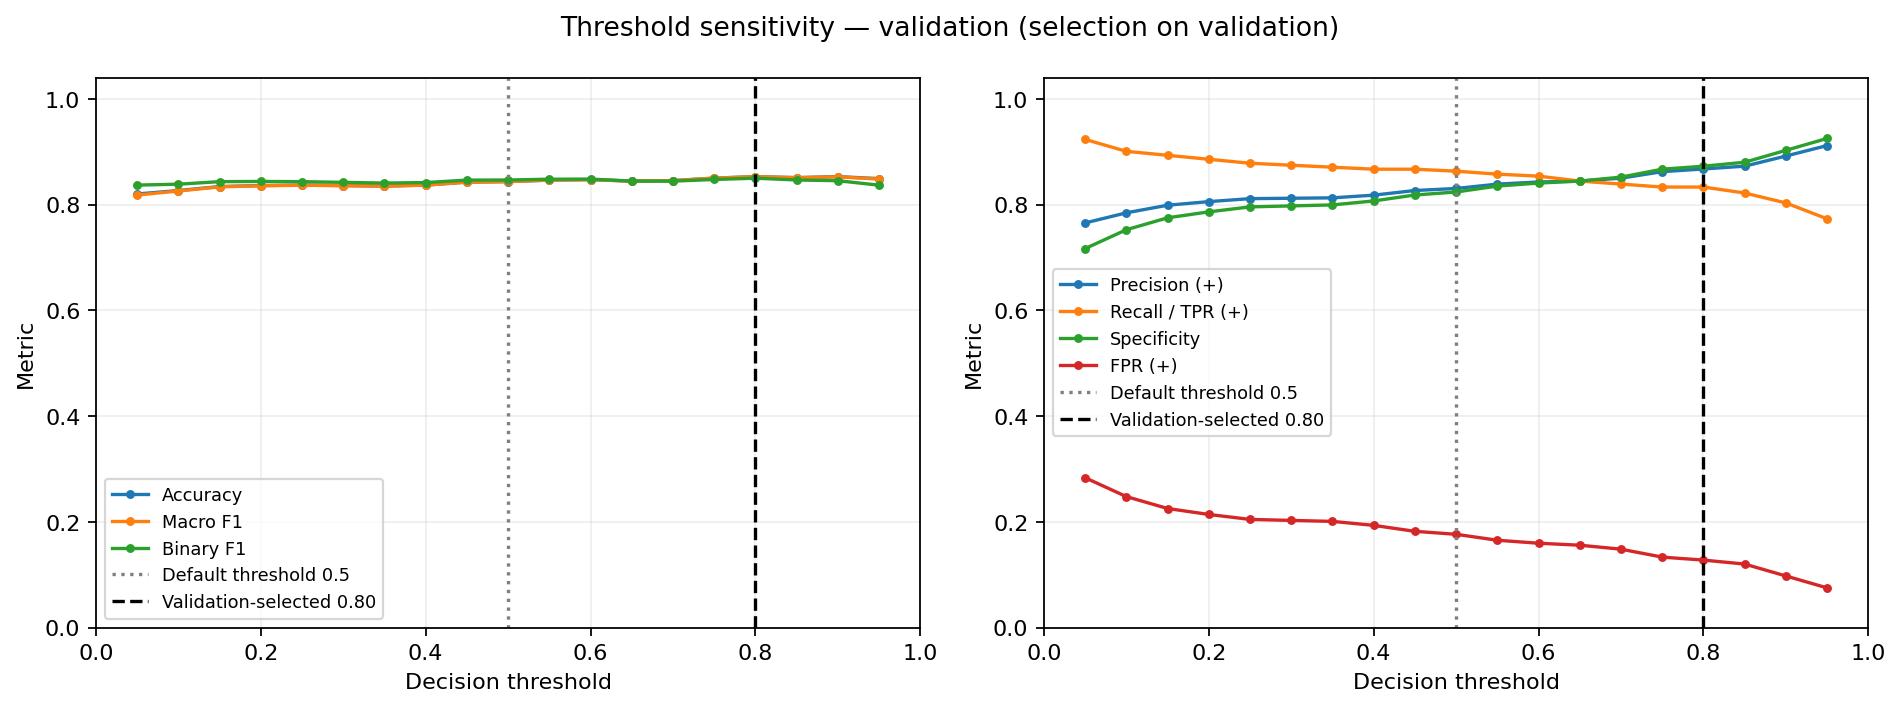

**Validation: so sánh threshold tham chiếu với threshold đã chọn**

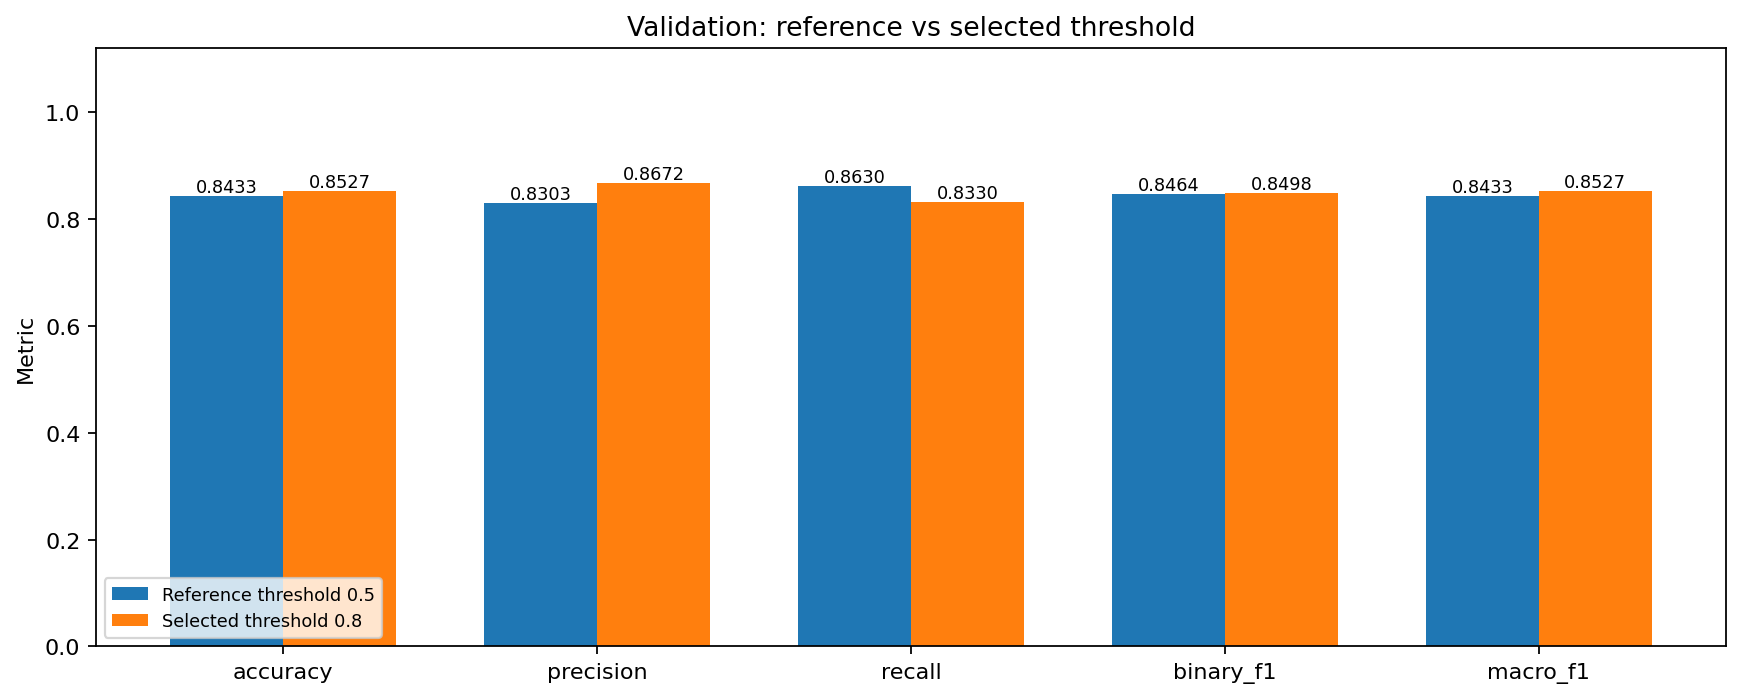

,threshold,accuracy,precision,recall,specificity,FPR,binary_f1,macro_f1,TN,FP,FN,TP,negative_support,positive_support,sample_count
0,0.05,0.819887,0.765163,0.923077,0.716698,0.283302,0.836735,0.817949,382,151,41,492,533,533,1066
1,0.10,0.826454,0.784314,0.900563,0.752345,0.247655,0.838428,0.825496,401,132,53,480,533,533,1066
2,0.15,0.833959,0.798658,0.893058,0.774859,0.225141,0.843224,0.833377,413,120,57,476,533,533,1066
3,0.20,0.835835,0.805461,0.885553,0.786116,0.213884,0.843610,0.835428,419,114,61,472,533,533,1066
4,0.25,0.836773,0.811092,0.878049,0.795497,0.204503,0.843243,0.836494,424,109,65,468,533,533,1066
5,0.30,0.835835,0.811847,0.874296,0.797373,0.202627,0.841915,0.835592,425,108,67,466,533,533,1066
6,0.35,0.834897,0.812609,0.870544,0.799250,0.200750,0.840580,0.834687,426,107,69,464,533,533,1066
7,0.40,0.836773,0.817699,0.866792,0.806754,0.193246,0.841530,0.836626,430,103,71,462,533,533,1066
8,0.45,0.842402,0.826476,0.866792,0.818011,0.181989,0.846154,0.842308,436,97,71,462,533,533,1066
9,0.50,0.843340,0.830325,0.863039,0.823640,0.176360,0.846366,0.843279,439,94,73,460,533,533,1066


**Test sensitivity diagnostic lịch sử; không dùng để chọn policy**

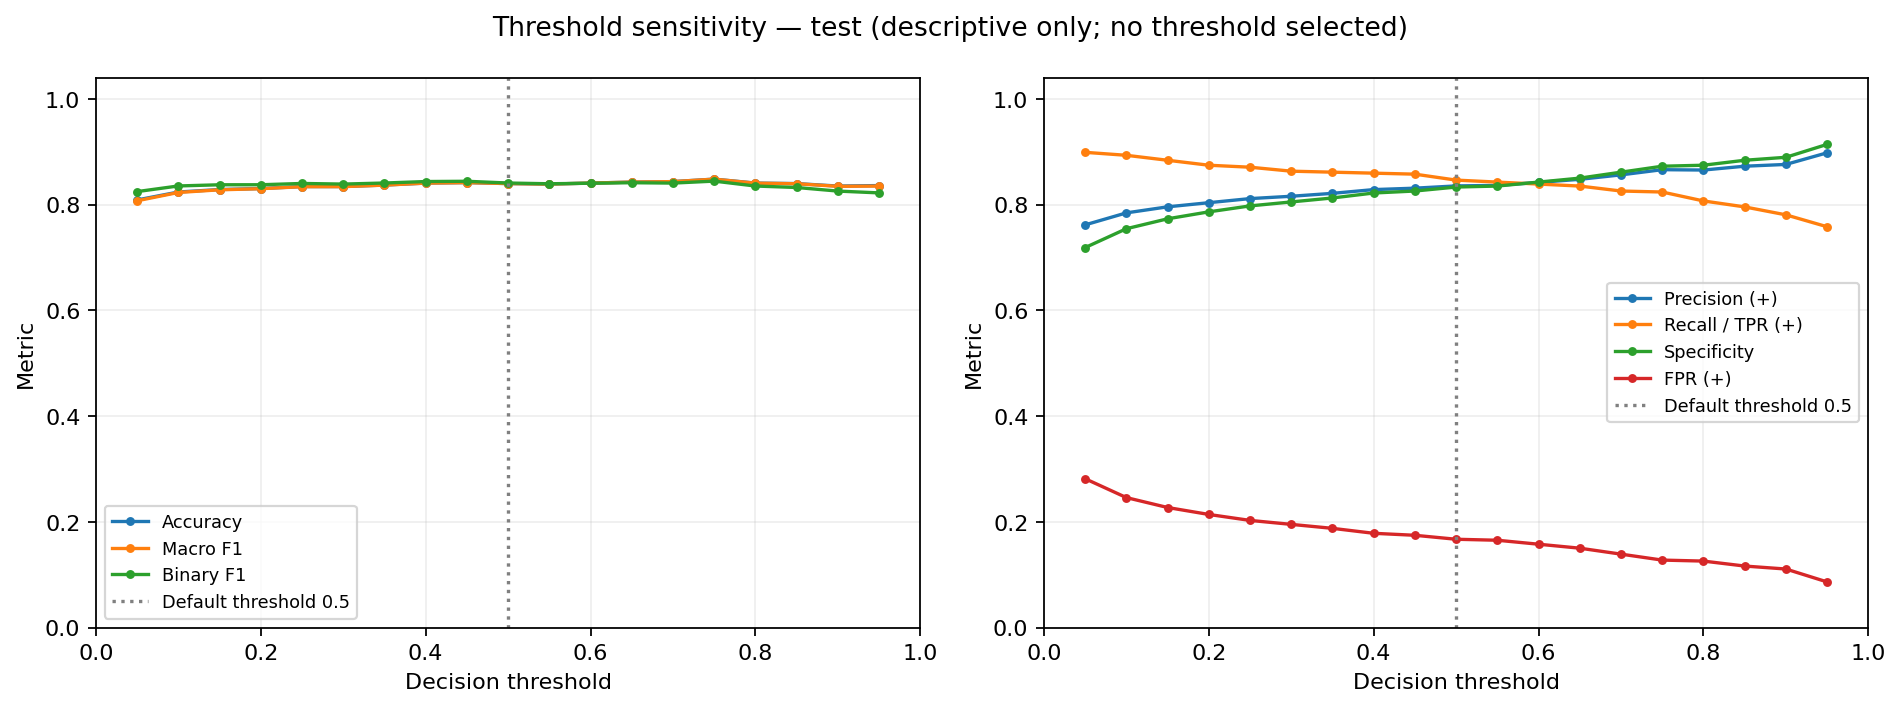

In [7]:
decision_path = finetuning_run / "decision_threshold.json"
if threshold_analysis_run:
    display(pd.DataFrame(threshold_tables["validation_comparison"]))
    show_figure(threshold_analysis_run / "validation_threshold_curves.png",
                "Quét 19 threshold trên validation; policy được đóng băng tại 0,8")
    show_figure(threshold_analysis_run / "validation_comparison.png",
                "Validation: so sánh threshold tham chiếu với threshold đã chọn")
    display(pd.DataFrame(threshold_tables["validation_grid"]))
elif decision_path.is_file():
    decision = read_json(decision_path)
    display(pd.DataFrame([decision["selected_metrics"]]))
    show_figure(finetuning_run / "validation_threshold/threshold_curves.png",
                "Threshold sweep trên validation của run mới")
else:
    display(Markdown("Run này chưa có policy validation. Khôi phục checkpoint rồi chạy select_threshold.py; không chọn ngưỡng từ test."))

show_figure(analysis_run / "threshold_test_diagnostic/threshold_curves.png",
            "Test sensitivity diagnostic lịch sử; không dùng để chọn policy")

### Phân biệt selection, evaluation và diagnostic

Selection chỉ đọc validation; `20261026T083612Z_evaluation_a724c16c` đọc policy đã đóng băng và đánh giá đủ 1.066 mẫu test. Bản policy lưu trong evaluation và inference phải giống selection, có SHA256 gắn với weights gốc. Module [threshold_evidence.py](../src/threshold_evidence.py) đối chiếu cả ba run và tính lại metrics; [threshold_analysis.py](../src/threshold_analysis.py) lưu bảng/ảnh so sánh trong run `threshold_analysis`.

Đường test diagnostic lịch sử chỉ mô tả độ nhạy, không chọn ngưỡng và không thay policy. Test đã được quan sát trong quá trình phát triển, nên không gọi lần đánh giá bổ sung này là một benchmark mù mới. Notebook `view` kiểm tra bằng chứng; không thực thi model khi weights không có ở máy đọc.


## 2.8. Đánh giá tổng thể và baseline

Accuracy đo tỉ lệ đúng; Precision Positive trả lời “trong các dự đoán Positive, bao nhiêu đúng?”; Recall trả lời “trong Positive thực, bao nhiêu được phát hiện?”. F1 là trung bình điều hòa Precision/Recall. Macro F1 trung bình đều F1 hai lớp, khác Binary F1 chỉ xét lớp Positive.

Baseline hằng Negative trên test cân bằng đạt Accuracy 50%, Macro F1 33,33%. Đây là baseline tính từ nhãn đã lưu, không phải accuracy giả định của backbone với classifier khởi tạo ngẫu nhiên. So sánh dưới đây dùng cùng test để mô tả mức cải thiện; không dùng test để chọn mô hình.

,model,accuracy,binary_precision,binary_recall,binary_f1,macro_precision,macro_recall,macro_f1
0,Constant NEGATIVE,0.500000,0.000000,0.000000,0.000000,0.250000,0.500000,0.333333
1,Fine-tuned DistilBERT (argmax),0.839587,0.835185,0.846154,0.840634,0.839646,0.839587,0.839580


**So sánh model với baseline hằng trên cùng test**

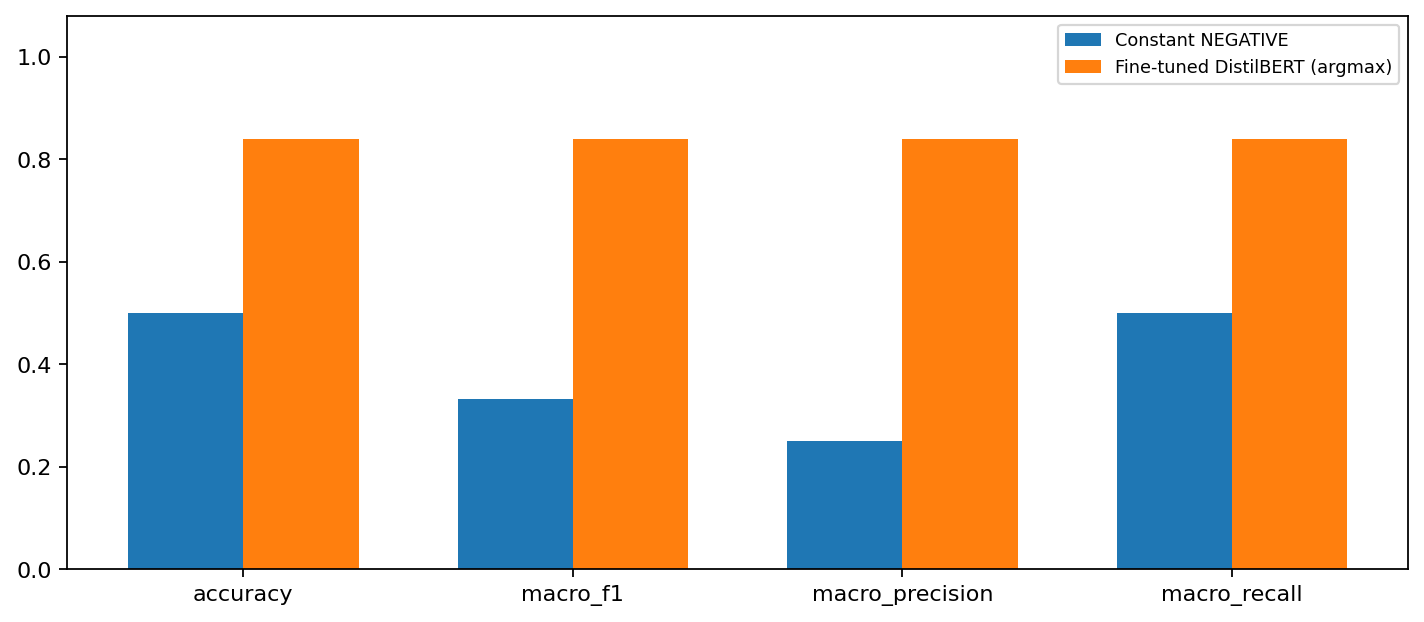

**Accuracy và Binary Precision/Recall/F1 của run gốc**

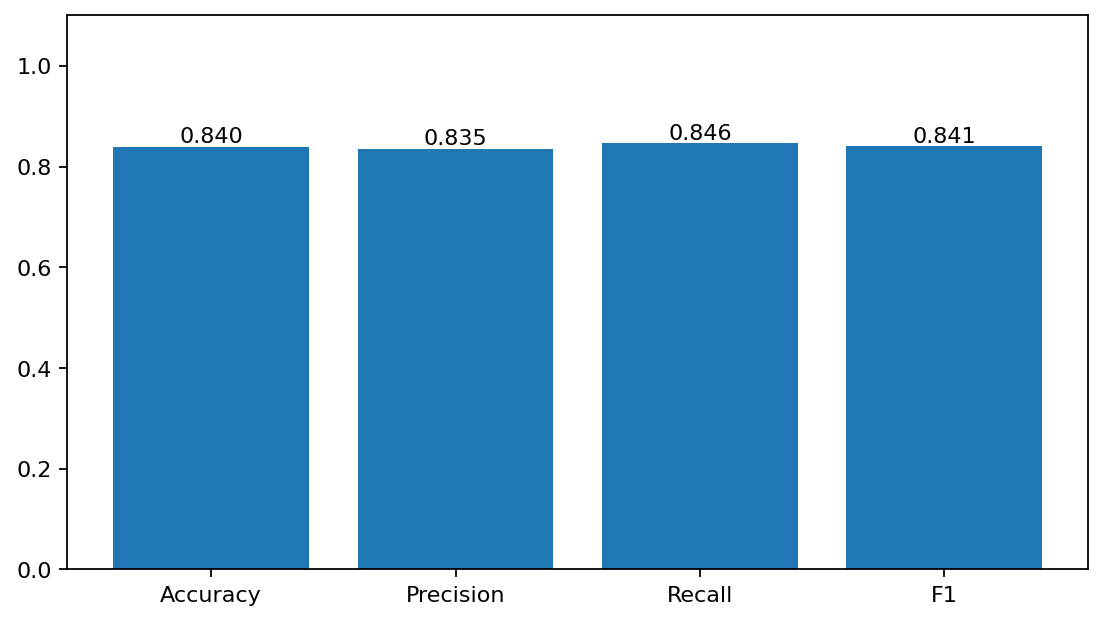

In [8]:
display(pd.DataFrame(analysis_tables["metrics_comparison"]))
show_figure(analysis_run / "metric_comparison.png", "So sánh model với baseline hằng trên cùng test")
show_figure(finetuning_run / "metrics_bar.png", "Accuracy và Binary Precision/Recall/F1 của run gốc")

### Test tại policy cố định: lợi ích nhỏ và đánh đổi lỗi

Cùng checkpoint, cùng 1.066 mẫu test: argmax đúng 895 mẫu, policy 0,8 đúng 896 mẫu. Positive Precision tăng **83,52% → 86,52%**, Recall giảm **84,62% → 80,68%**; Binary F1 giảm **84,06% → 83,50%**. Macro F1 tăng nhẹ **83,9580% → 84,0343%**. Không quét lại để tối ưu test.

Loss đo sau reload là **0,5442678** cho cùng probabilities ở cả hai quy tắc. Nó khác reconstructed NLL của probabilities FP16 lịch sử (~0,5442964); không ghi đè loss chưa được log ở training run cũ.


,method,accuracy,precision,recall,binary_f1,macro_f1,threshold,specificity,FPR,TN,FP,FN,TP,negative_support,positive_support,sample_count,selection_split,selection_performed_on_test
0,Argmax,0.839587,0.835185,0.846154,0.840634,0.839580,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Validation threshold 0.8,0.840525,0.865191,0.806754,0.834951,0.840343,0.8,0.874296,0.125704,466.0,67.0,103.0,430.0,533.0,533.0,1066.0,validation,False


**Test metrics của argmax và policy validation đã đóng băng**

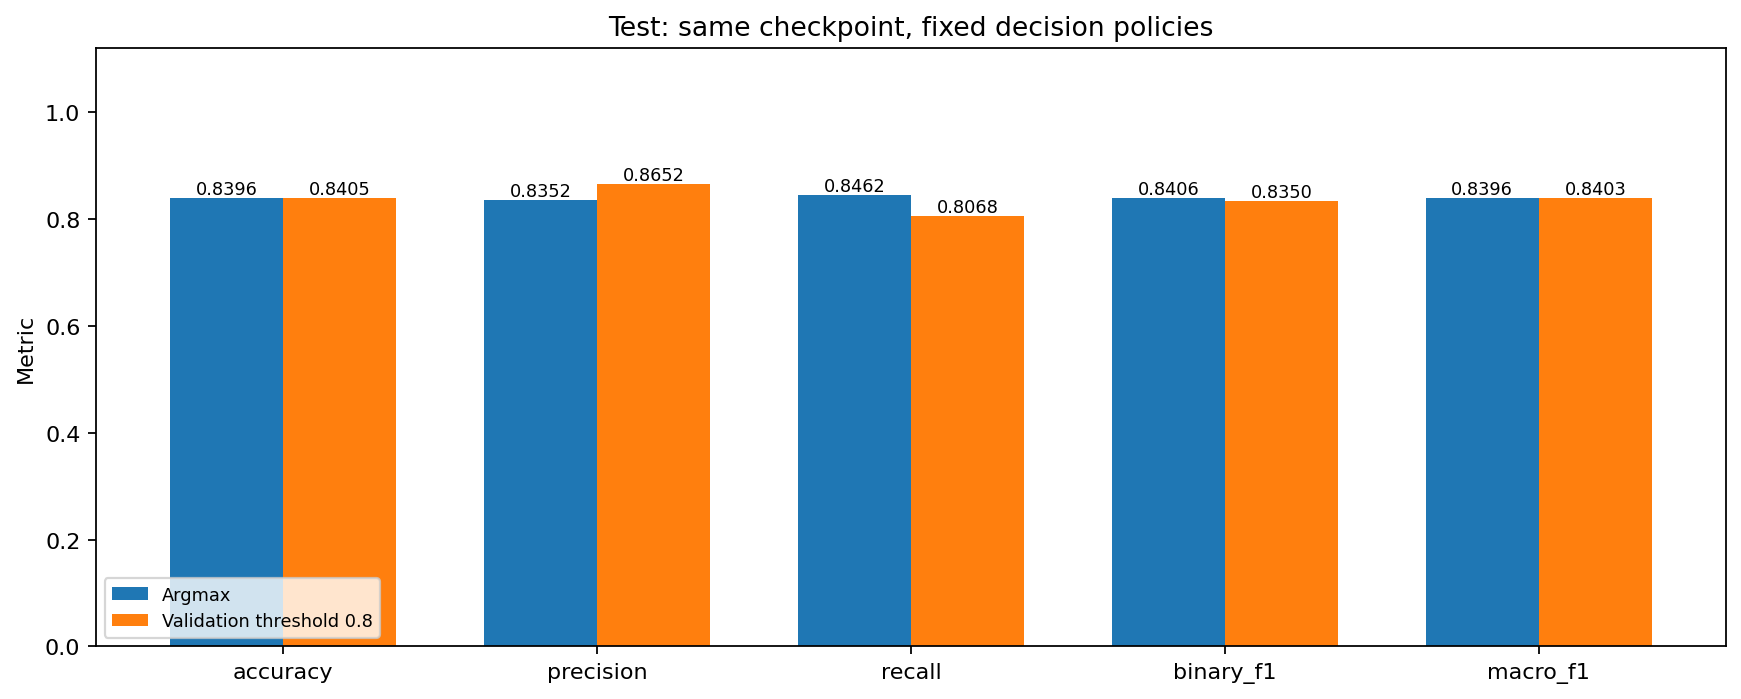

**Hai confusion matrices cùng thang màu và cùng test support**

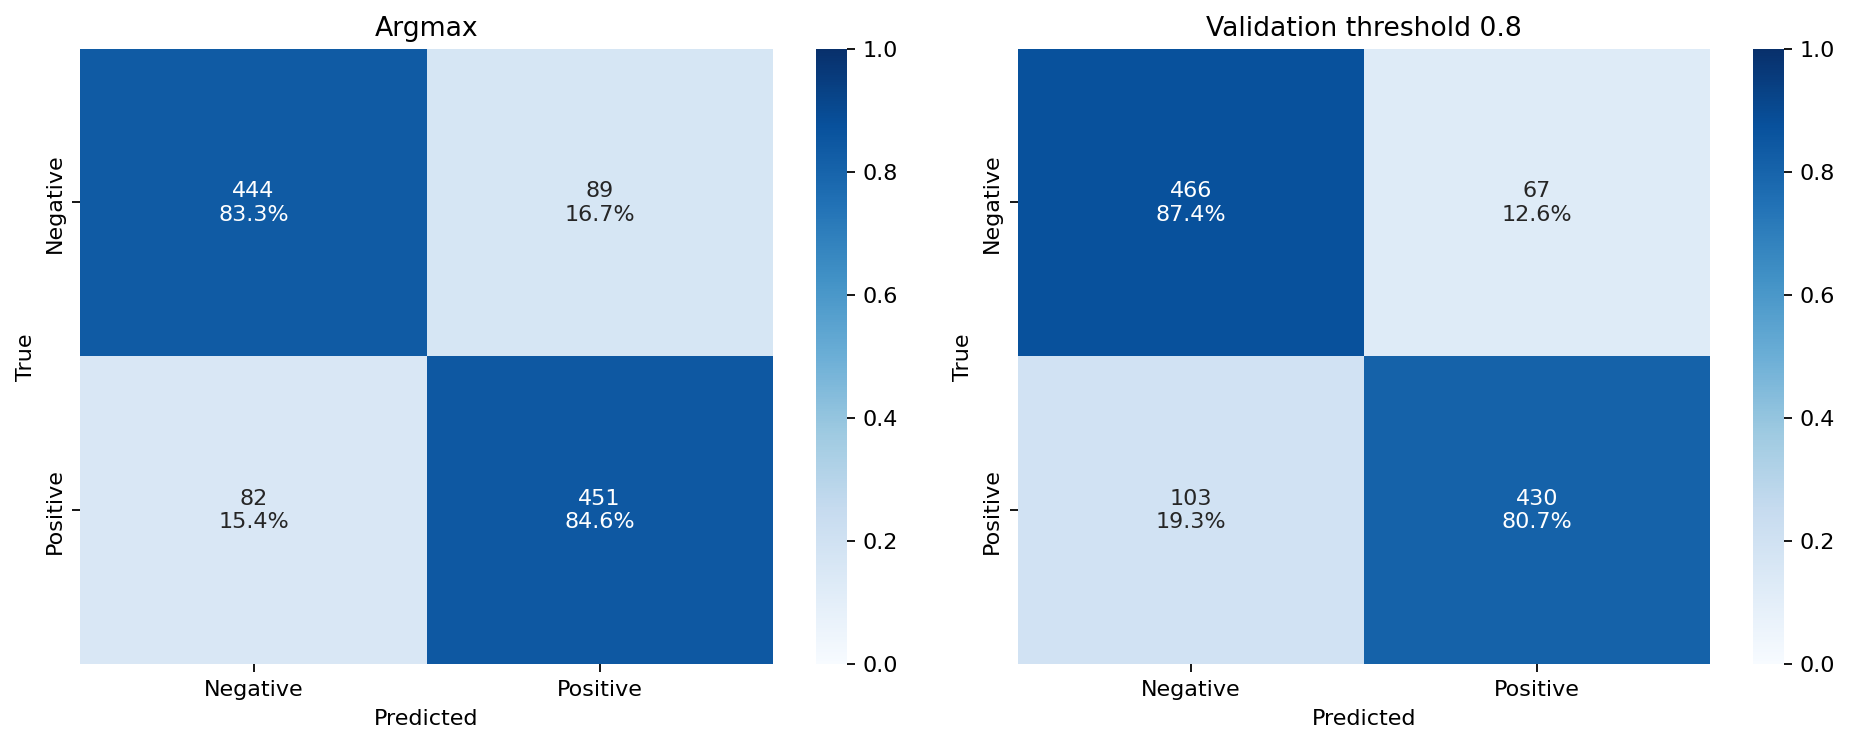

**22 lỗi được sửa, 21 lỗi mới phát sinh: tăng một mẫu đúng**

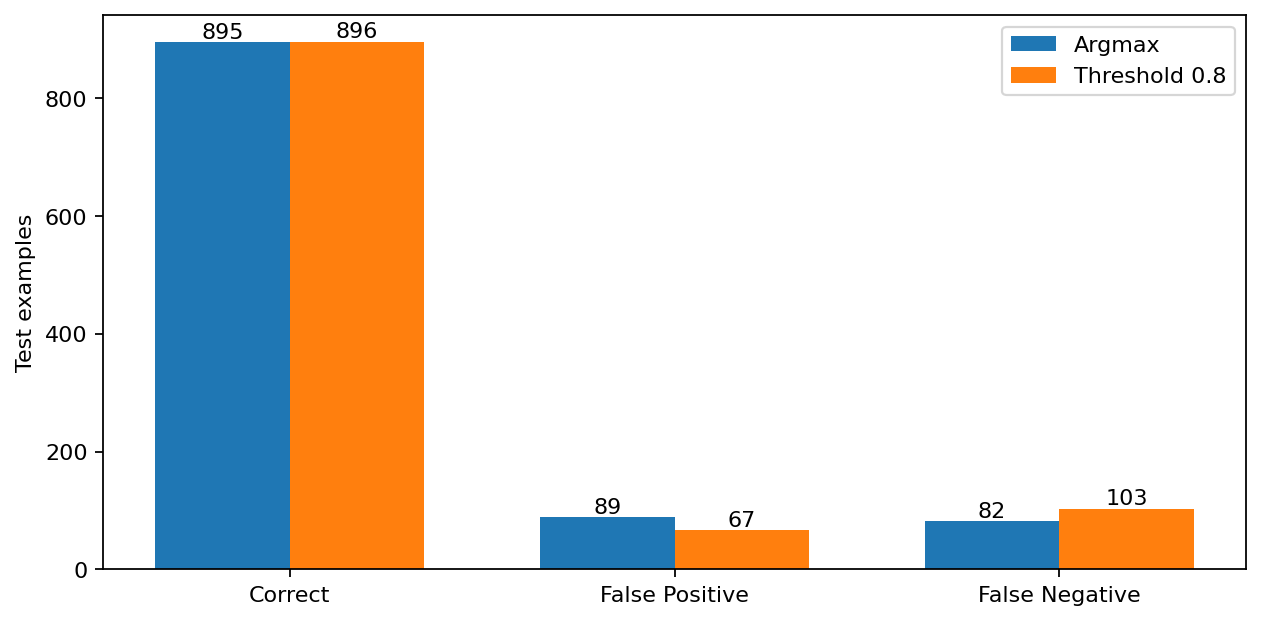

Measured test loss sau reload: 0.5442677736282349


In [9]:
if threshold_analysis_run:
    display(pd.DataFrame(threshold_tables["test_comparison"]))
    show_figure(threshold_analysis_run / "test_comparison.png", "Test metrics của argmax và policy validation đã đóng băng")
    show_figure(threshold_analysis_run / "confusion_comparison.png", "Hai confusion matrices cùng thang màu và cùng test support")
    show_figure(threshold_analysis_run / "error_tradeoff.png", "22 lỗi được sửa, 21 lỗi mới phát sinh: tăng một mẫu đúng")
    print("Measured test loss sau reload:", threshold_summary["test_loss"])


## 2.9. Confusion matrix và metric từng lớp

Confusion matrix dùng hàng là nhãn thật, cột là dự đoán. Với Positive là lớp dương: TP=451, TN=444, FP=89, FN=82 ở run tham chiếu. Accuracy bằng `(TP+TN)/N`; FPR bằng `FP/(FP+TN)`.

Hình có count và tỷ lệ chuẩn hóa theo từng hàng, không chuẩn hóa toàn ma trận. TPR của Negative thấp hơn Positive; số Negative đoán nhầm Positive là 89, lớn hơn 82 ở chiều ngược lại. Bảng one-vs-rest cho từng lớp làm rõ lớp nào dễ bị bỏ sót và lớp nào dễ nhận False Positives.

,label,precision,recall_TPR,F1,FPR,support
0,NEGATIVE,0.844106,0.833021,0.838527,0.153846,533
1,POSITIVE,0.835185,0.846154,0.840634,0.166979,533


**Confusion matrix: số lượng và tỷ lệ theo hàng**

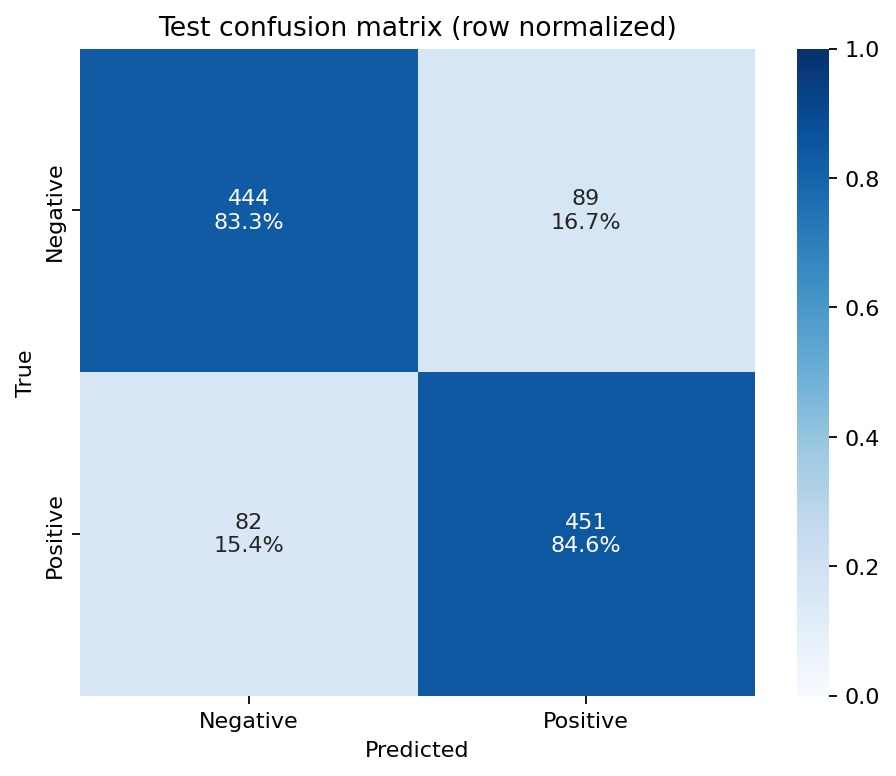

**Precision, Recall/TPR, F1 và FPR từng lớp**

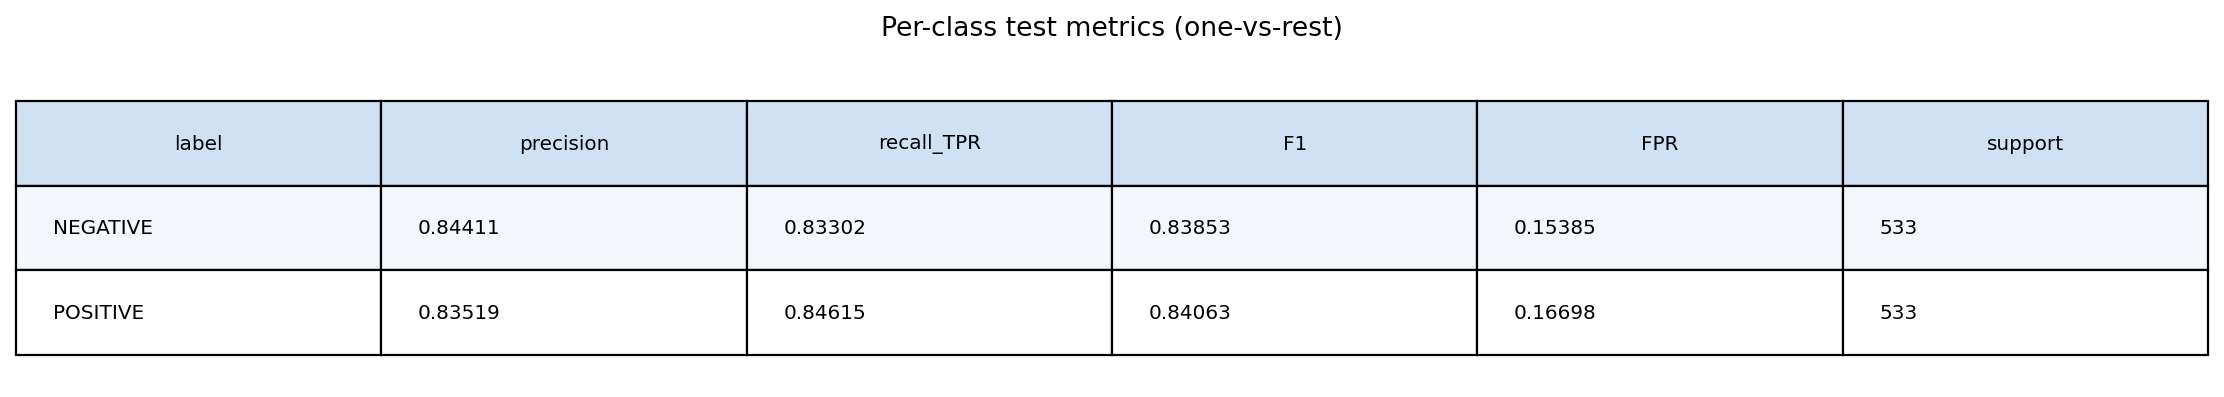

In [10]:
display(pd.DataFrame(analysis_tables["per_class_metrics"]))
show_figure(finetuning_run / "confusion_matrix.png", "Confusion matrix: số lượng và tỷ lệ theo hàng")
show_figure(analysis_run / "per_class_metrics.png", "Precision, Recall/TPR, F1 và FPR từng lớp")

## 2.10. ROC, Precision–Recall và cách hiểu AUC

ROC vẽ TPR theo FPR khi thay threshold. ROC-AUC đo khả năng xếp hạng Positive cao hơn Negative, không phải accuracy tại một threshold. Precision–Recall tập trung vào chất lượng phát hiện Positive; Average Precision tổng hợp precision theo recall, không đồng nhất với ROC-AUC.

Các curve test ở đây là **mô tả** từ xác suất test đã lưu. Không chọn lại checkpoint hoặc threshold bằng cách tìm điểm đẹp nhất trên các curve test.

**Test ROC và Precision–Recall từ probabilities thật**

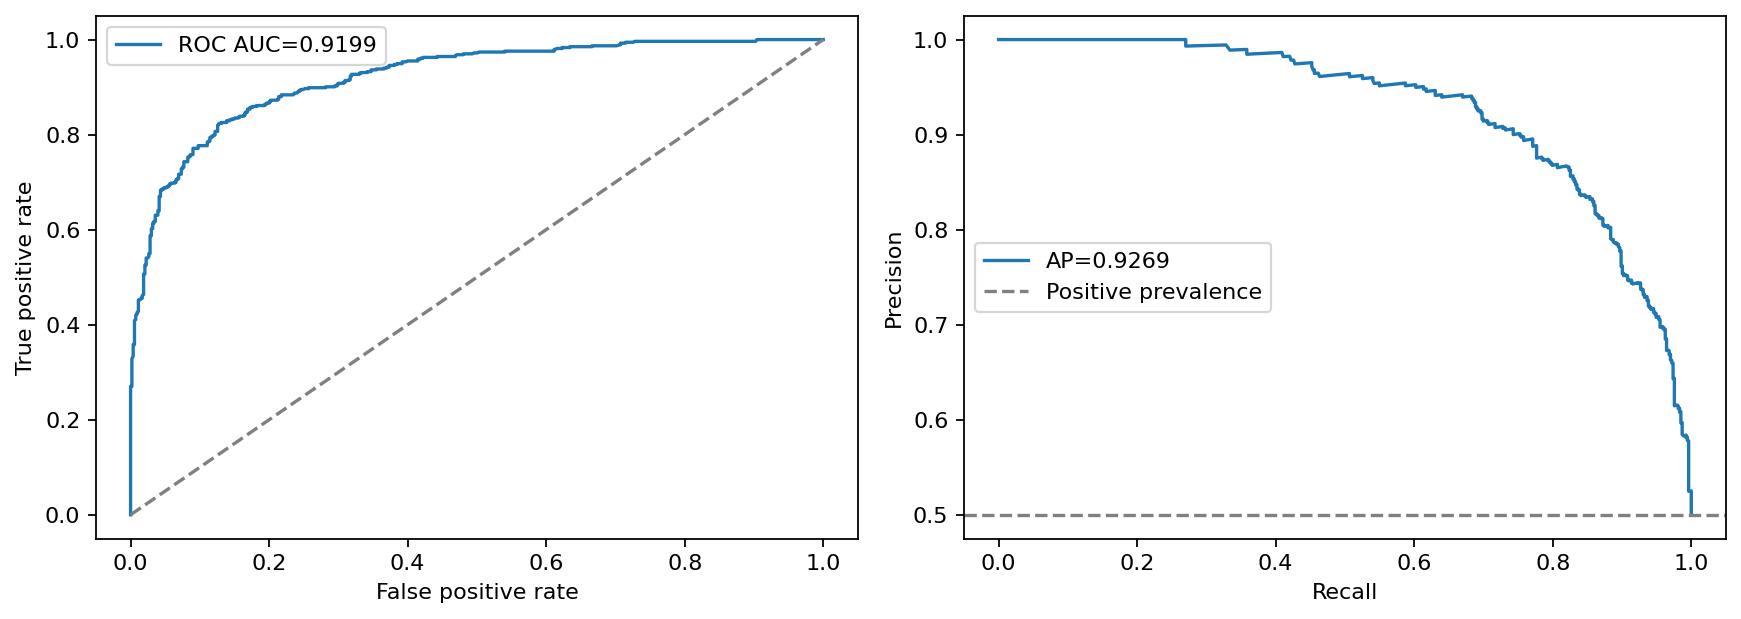

ROC-AUC: 0.9199493820598474
Average Precision: 0.9268528694509572


In [11]:
show_figure(analysis_run / "roc_pr_curves.png", "Test ROC và Precision–Recall từ probabilities thật")
print("ROC-AUC:", analysis_summary["roc_auc"])
print("Average Precision:", analysis_summary["average_precision"])

## 2.11. Confidence, phân bố xác suất và calibration

Hai mô hình có cùng accuracy vẫn có thể đưa ra confidence khác nhau. Reliability diagram so sánh confidence với tỷ lệ đúng trong từng bin; ECE tổng hợp khoảng cách theo trọng số bin. Giá trị ECE phụ thuộc cách chia bin và không phải bảo đảm phổ quát. Brier score đo sai số bình phương của xác suất Positive so với nhãn 0/1.

Biểu đồ xác suất giúp nhìn mức phân tách hai lớp và những dự đoán gần biên. Các lỗi có confidence cao cho thấy tự tin không bảo đảm đúng; chỉ đọc vài ví dụ sai không đủ kết luận calibration, nên cần xem cả biểu đồ và thước đo trên toàn bộ test đã lưu.

**Phân bố xác suất Positive theo nhãn thật**

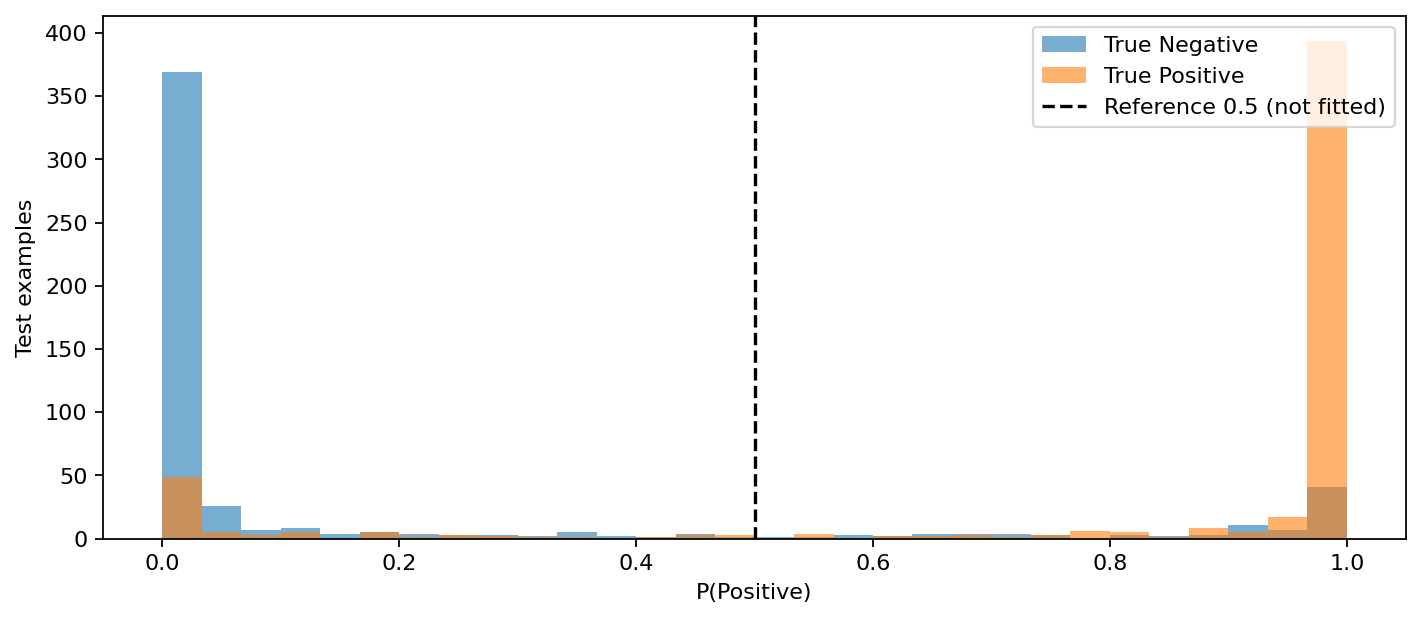

**Reliability / calibration diagnostic trên test**

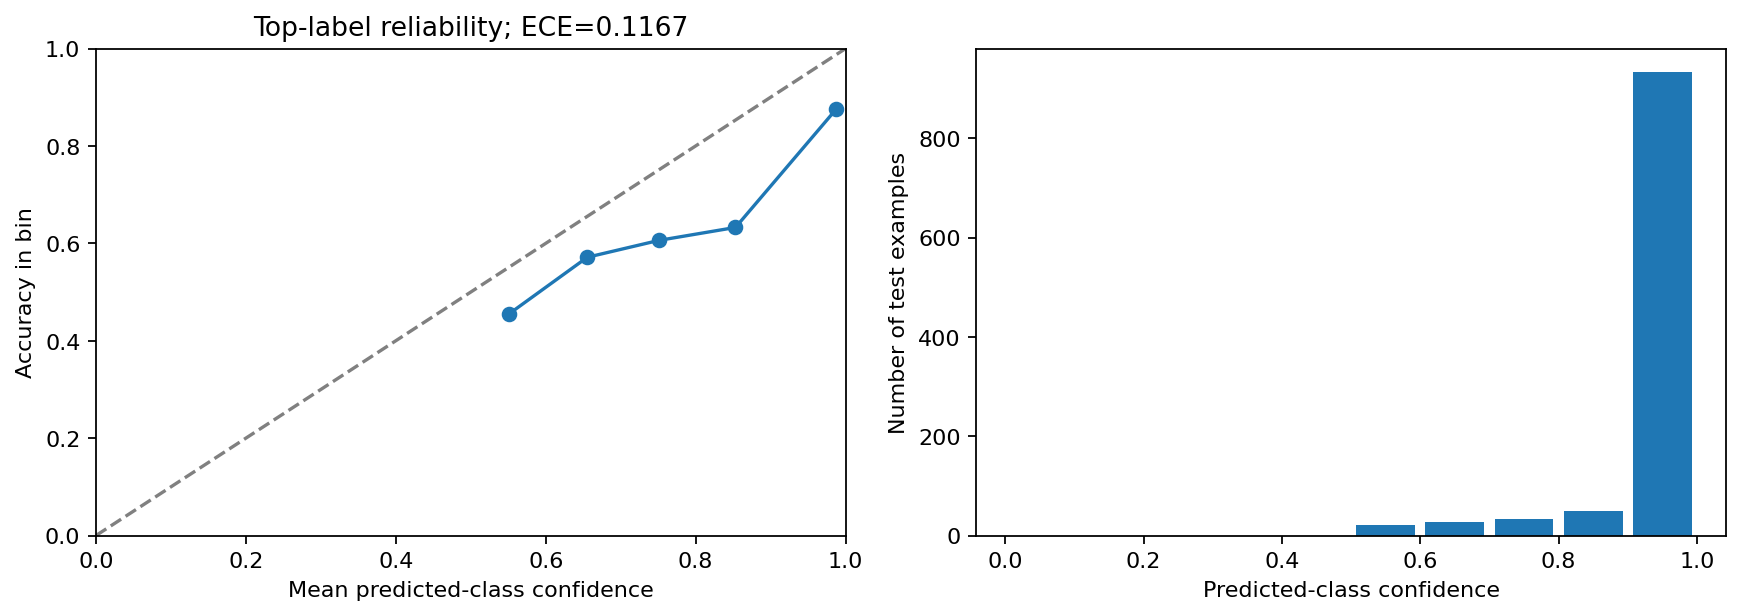

Confidence ECE: 0.11673777216370963
Brier score: 0.13614091824837452


In [12]:
show_figure(analysis_run / "probability_distribution.png", "Phân bố xác suất Positive theo nhãn thật")
show_figure(analysis_run / "calibration_curve.png", "Reliability / calibration diagnostic trên test")
print("Confidence ECE:", analysis_summary["confidence_ece"])
print("Brier score:", analysis_summary["brier_score"])

## 2.12. Phân tích định tính các lỗi

Các mẫu được chọn theo confidence cao của cả nhóm đúng/sai và cả hai nhãn, không phải một mẫu ngẫu nhiên đại diện test. Diễn giải ngôn ngữ dưới đây là giả thuyết, không phải bằng chứng về nguyên nhân bên trong attention hay classifier.

- **Hey Arnold:** “barely feature length” là chê, nhưng “appealing” và lời khen animation có thể làm tín hiệu tích cực lấn át. Điểm khó là trộn hai chiều cảm xúc.
- **Disney:** “entertains … perverse pleasure … scrape the bottom …” mang tính mỉa mai. Một từ như “entertains” không đủ để quyết định sentiment của cả câu.
- **Story is almost an afterthought:** “afterthought”, “inexplicable” có vẻ tiêu cực, nhưng câu được dataset gán Positive trong đánh giá trải nghiệm thị giác. Không tự kết luận nhãn sai chỉ vì câu mơ hồ.
- **The Wild Thornberrys:** “rivalry”, “chaos” mô tả nội dung gia đình, còn “anyone can relate” thể hiện đồng cảm tích cực. Từ vựng cốt truyện khác với thái độ của người nhận xét.

**Ví dụ đúng/sai có confidence cao; xanh đúng, đỏ sai**

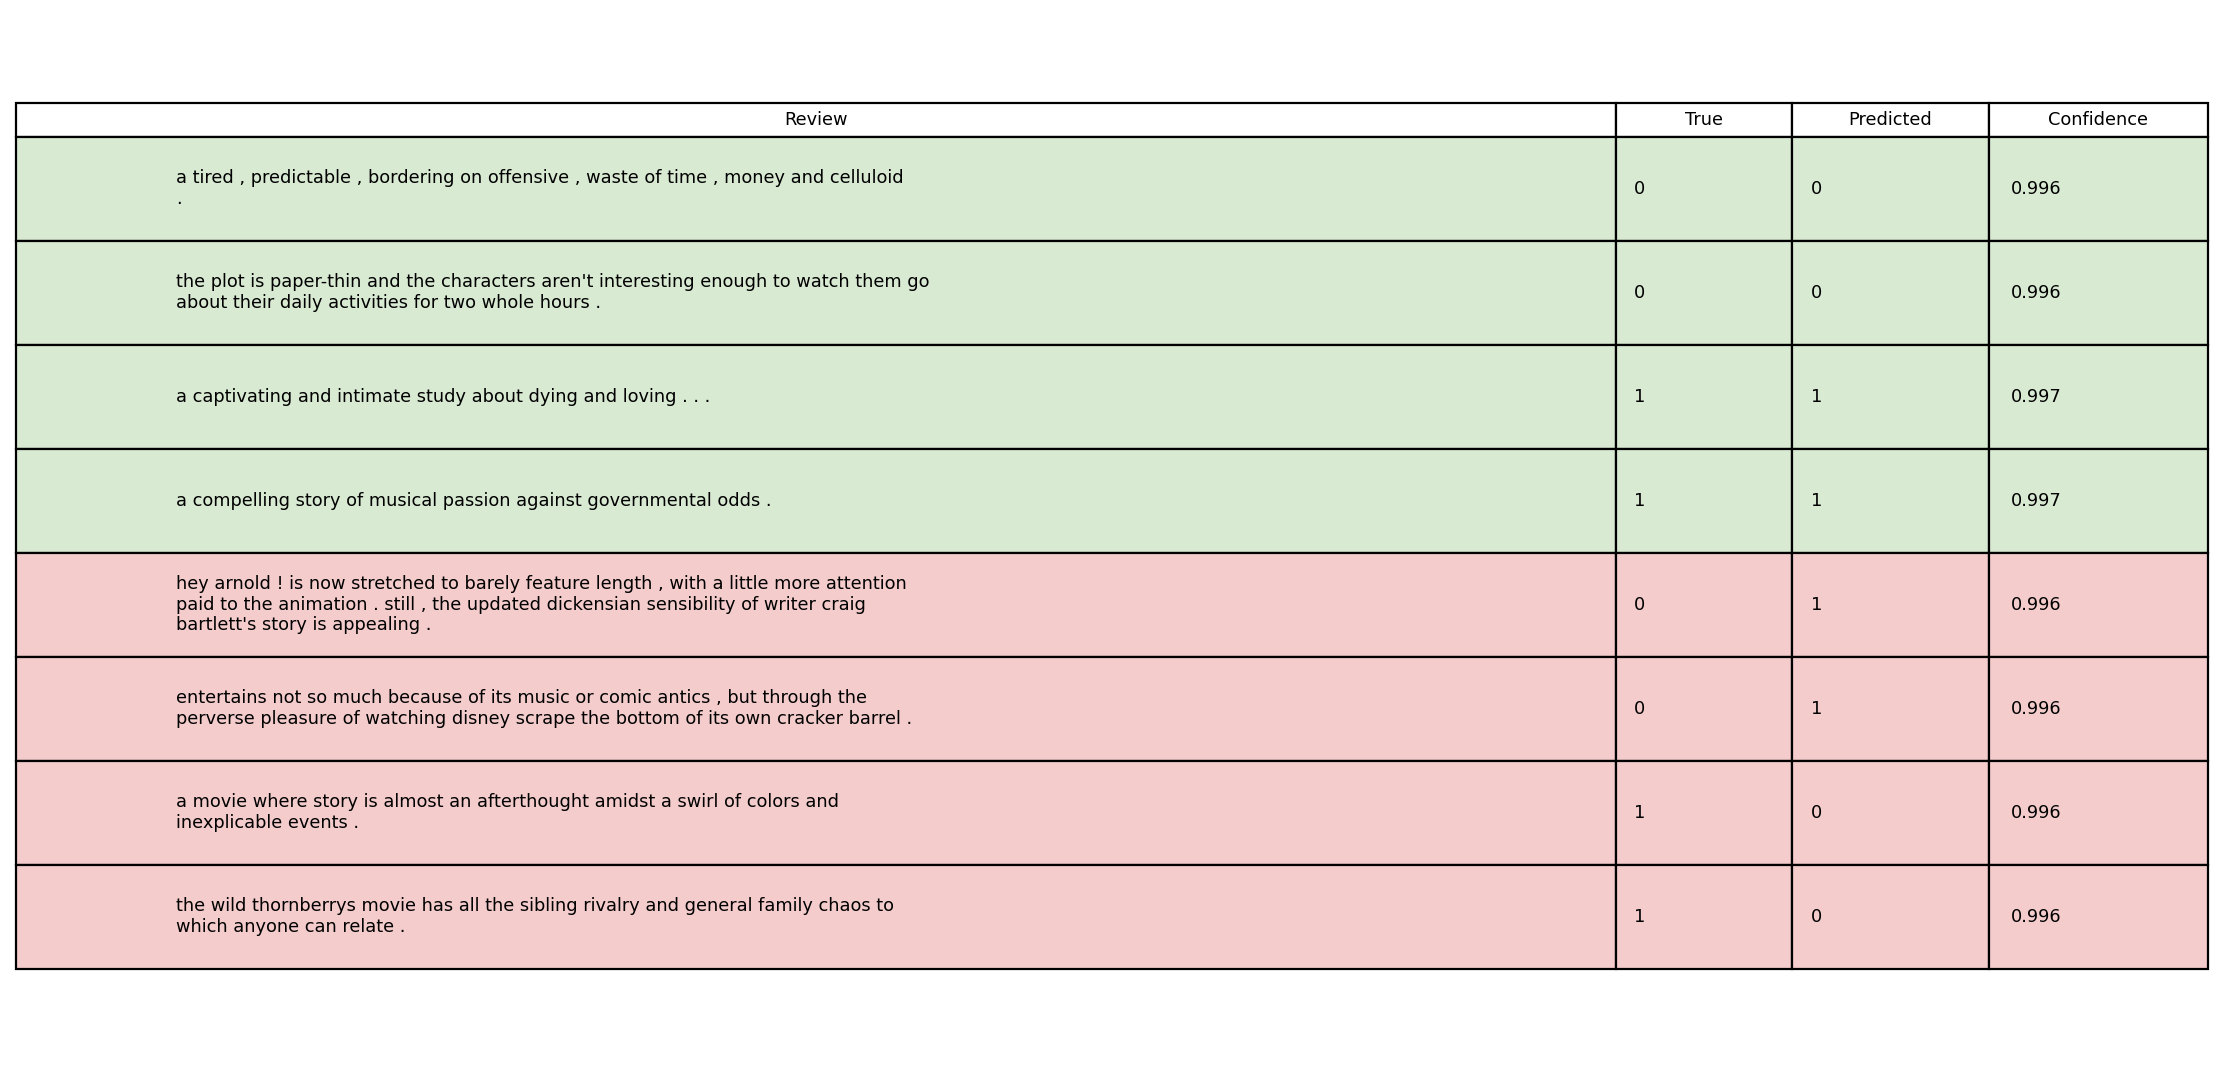

,index,text,true_label,predicted_label,confidence
0,823,"a tired , predictable , bordering on offensive...",0,0,0.996413
1,1017,the plot is paper-thin and the characters aren...,0,0,0.996322
2,85,a captivating and intimate study about dying a...,1,1,0.997054
3,465,a compelling story of musical passion against ...,1,1,0.997025
4,1014,hey arnold ! is now stretched to barely featur...,0,1,0.996078
5,939,entertains not so much because of its music or...,0,1,0.995826
6,219,a movie where story is almost an afterthought ...,1,0,0.995609
7,470,the wild thornberrys movie has all the sibling...,1,0,0.995609


In [13]:
show_figure(finetuning_run / "sample_predictions.png", "Ví dụ đúng/sai có confidence cao; xanh đúng, đỏ sai")
display(pd.DataFrame(read_json(finetuning_run / "sample_predictions.json")))

### Những dự đoán thay đổi và sử dụng policy khi inference

Bảng dưới lấy hai ví dụ thật mỗi nhóm: lỗi được sửa, lỗi mới phát sinh, quyết định không đổi; đây là mẫu minh họa có chủ đích. Khi tăng ngưỡng lên 0,8, các câu có xác suất Positive từ 0,5 đến dưới 0,8 chuyển sang Negative. Model weights không đổi.

Inference bổ sung dùng đúng policy và checkpoint gốc. Câu có hai vế tương phản được gán Negative, xác suất Negative khoảng 0,99333. Một ví dụ không đo được accuracy ngoài phân phối; chỉ chứng minh dòng sử dụng policy và xuất artifact.


,method,label,precision,recall_TPR,F1,FPR,support
0,Argmax,NEGATIVE,0.844106,0.833021,0.838527,0.153846,533
1,Argmax,POSITIVE,0.835185,0.846154,0.840634,0.166979,533
2,Threshold 0.8,NEGATIVE,0.818981,0.874296,0.845735,0.193246,533
3,Threshold 0.8,POSITIVE,0.865191,0.806754,0.834951,0.125704,533


**Precision, Recall/TPR, F1, FPR từng lớp ở hai policy**

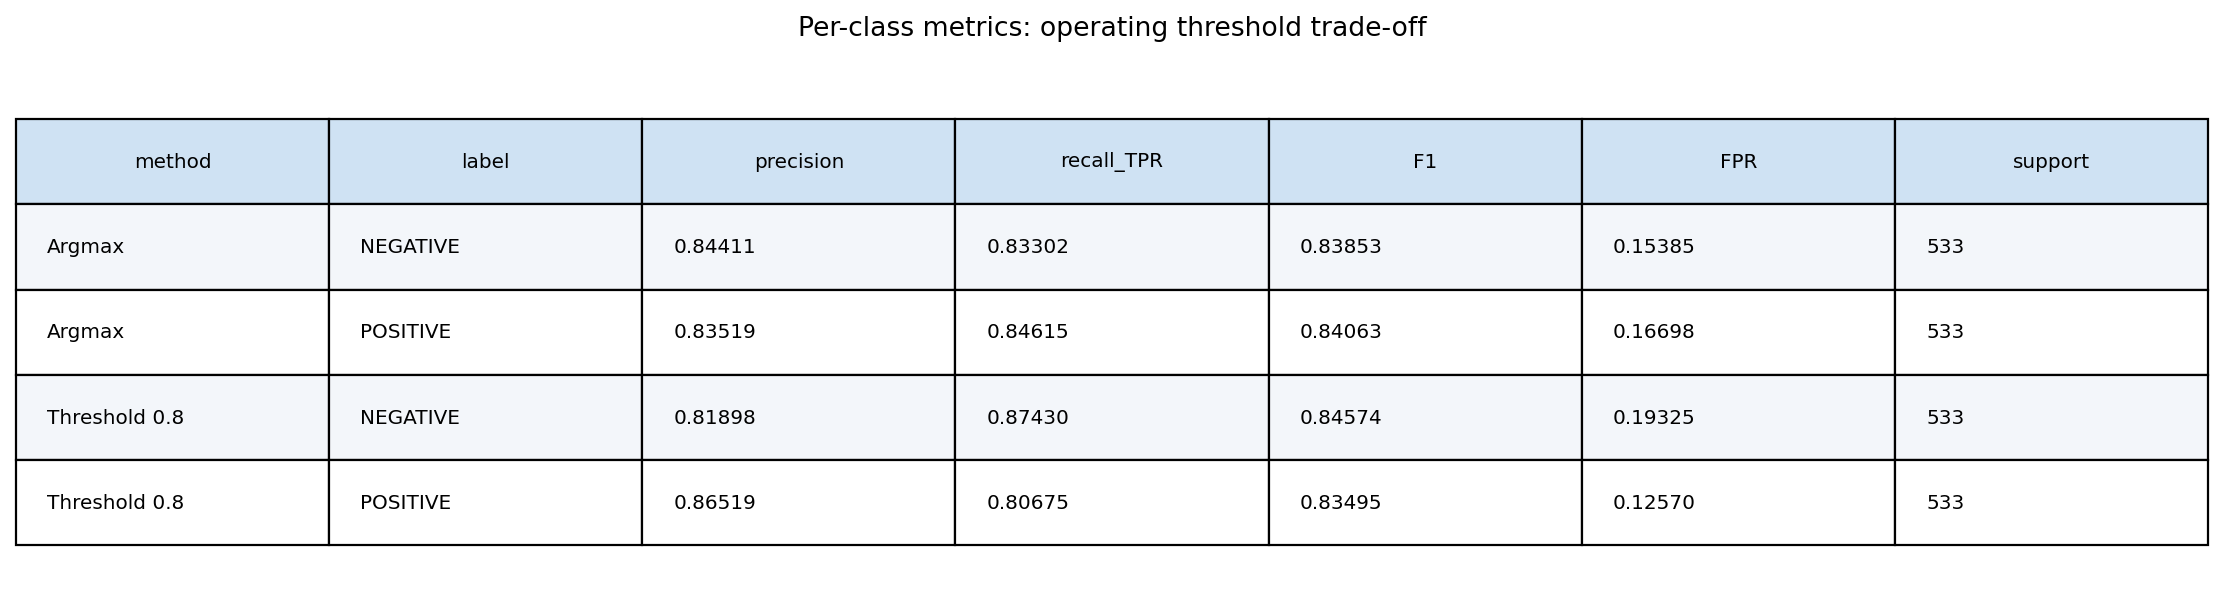

**Ví dụ bị tác động bởi threshold: đọc cả lỗi sửa được và lỗi phát sinh**

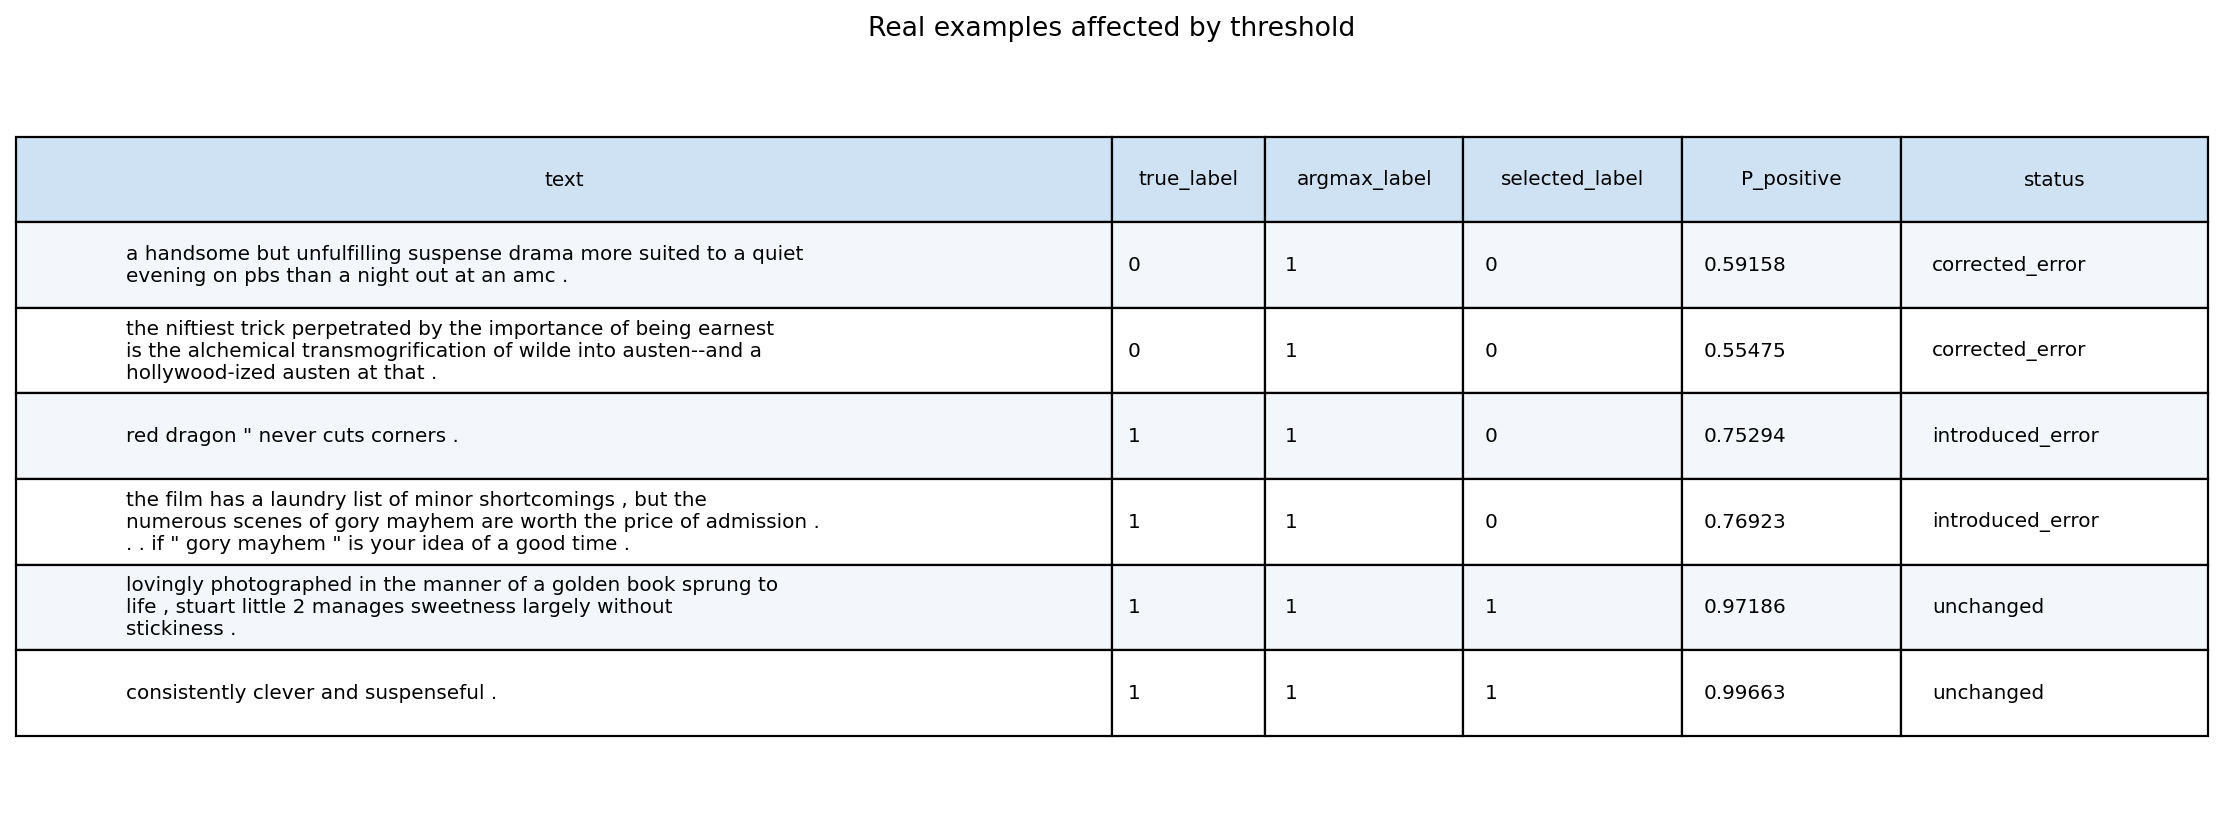

**Hai điểm vận hành trên ROC/PR của cùng probabilities sau reload**

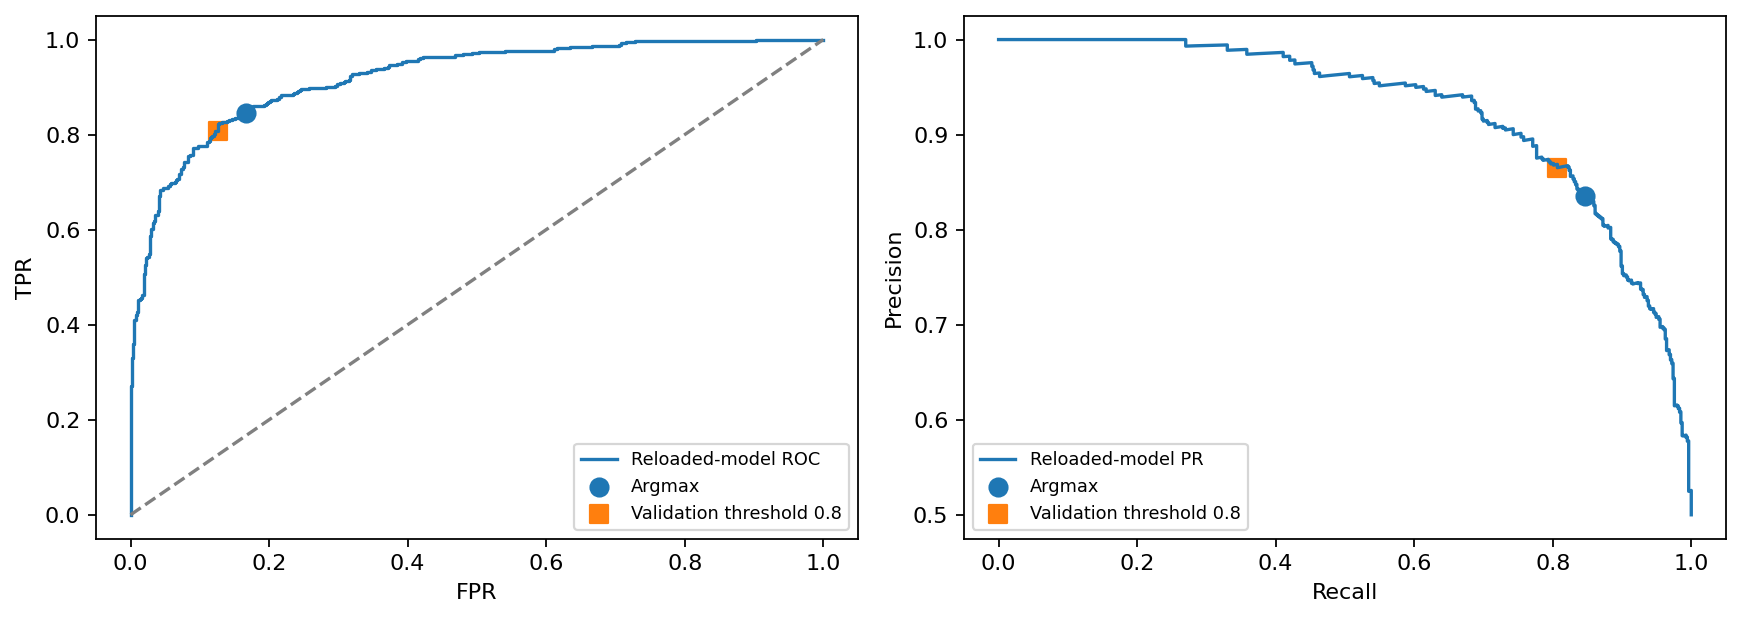

**Inference thật từ checkpoint và policy validation 0,8**

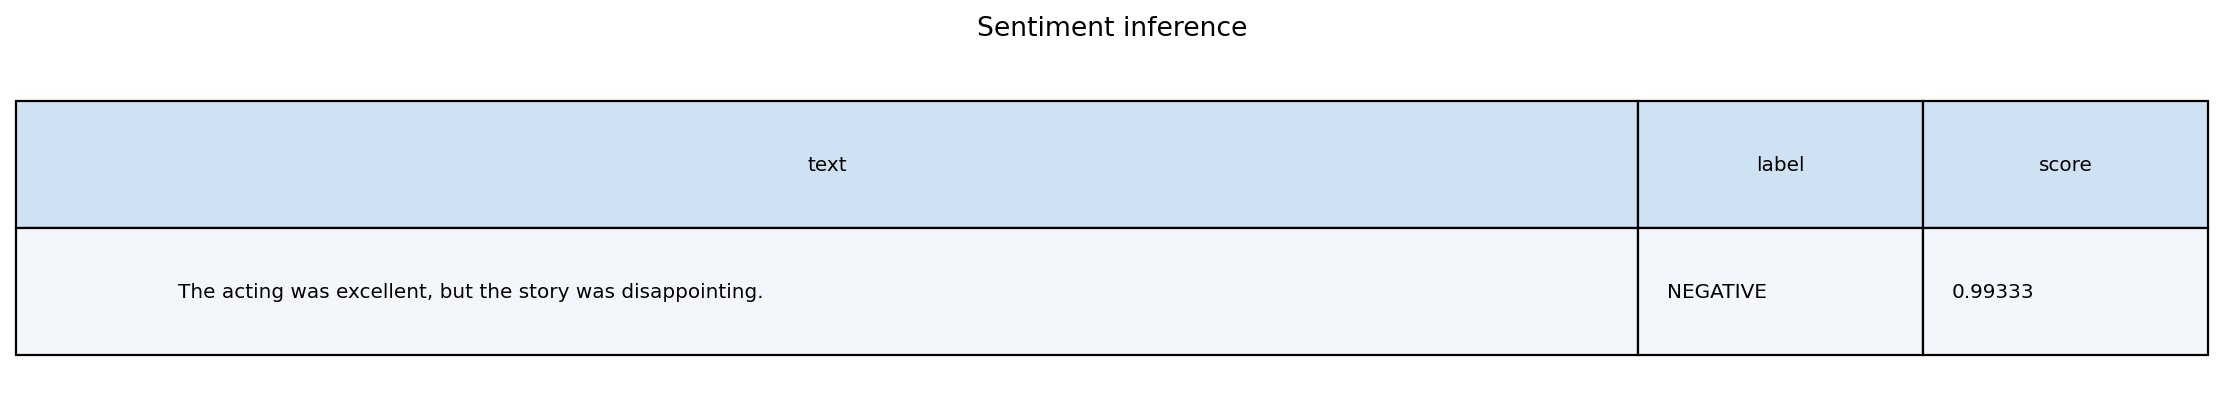

Nguồn run và kết luận đã lưu: /workspace/Lab-DL/labs/lab03/outputs/runs/20261026T124315Z_threshold_analysis_8bc30b27/summary.json


In [14]:
if threshold_analysis_run:
    display(pd.DataFrame(threshold_tables["per_class_comparison"]))
    show_figure(threshold_analysis_run / "per_class_comparison.png", "Precision, Recall/TPR, F1, FPR từng lớp ở hai policy")
    show_figure(threshold_analysis_run / "changed_predictions.png", "Ví dụ bị tác động bởi threshold: đọc cả lỗi sửa được và lỗi phát sinh")
    show_figure(threshold_analysis_run / "operating_points.png", "Hai điểm vận hành trên ROC/PR của cùng probabilities sau reload")
    show_figure(threshold_analysis_run / "inference_result.png", "Inference thật từ checkpoint và policy validation 0,8")
    print("Nguồn run và kết luận đã lưu:", threshold_analysis_run / "summary.json")


## 2.13. Save/load, artifact và kiểm chứng

Mỗi run có config, môi trường, console log, status, metadata và SHA256 manifest. Kaggle đã lưu checkpoint tốt nhất và ghi `reload_check.json`: trọng số khớp chính xác, forward đối chiếu trong cùng CPU FP32. GitHub không giữ trọng số lớn; notebook view chỉ đọc bằng chứng đã lưu, không tải lại model lần nữa.

Audit độc lập kiểm tra hash của file hiện có, 1.066 index test, phân bố nhãn 533/533, probability hợp lệ, nhãn argmax và tính lại bảy metrics. SHA256 chứng minh bytes giữ nguyên so với manifest, không chứng minh một thí nghiệm đúng về khoa học. Run lịch sử chỉ ghi reload check nhỏ; run evaluation bổ sung đã tải lại checkpoint trên Kaggle và đánh giá đủ test. Measured test loss là 0,5442677736; loss phụ thuộc probabilities, không phụ thuộc ngưỡng quyết định. Bản audit mới kiểm tra thêm 32 file nguồn và tính lại loss gần khớp từ probabilities với tolerance số học.

Tất cả hình mới được lưu trong run phân tích và tất cả bảng có file nguồn JSON. Không dùng một hình chỉ nằm tạm trong notebook làm bằng chứng duy nhất.

In [15]:
display(pd.DataFrame(analysis_tables["artifact_catalog"]))
print("Bằng chứng reload đã chạy trên Kaggle:")
display(read_json(finetuning_run / "reload_check.json"))
print("Tóm tắt phân tích đã lưu:", analysis_run / "analysis_summary.json")
print("Bảng đã lưu:", analysis_run / "tables.json")

,file,source_run
0,confusion_matrix.png,20261025T181550Z_finetuning_e02bced7
1,learning_curves.png,20261025T181550Z_finetuning_e02bced7
2,metrics_bar.png,20261025T181550Z_finetuning_e02bced7
3,sample_predictions.png,20261025T181550Z_finetuning_e02bced7
4,token_length_distribution.png,20261025T181550Z_finetuning_e02bced7


Bằng chứng reload đã chạy trên Kaggle:


{'weights_exact_match': True,
 'execution': 'CPU FP32, clean forward methods',
 'predictions': [{'text': 'lovingly photographed in the manner of a golden book sprung to life , stuart little 2 manages sweetness largely without stickiness .',
   'label': 'POSITIVE',
   'score': 0.9718583226203918,
   'probabilities': [0.02814166434109211, 0.9718583226203918]}]}

Tóm tắt phân tích đã lưu: /workspace/Lab-DL/labs/lab03/outputs/runs/20261026T080403Z_analysis_7b9e92eb/analysis_summary.json
Bảng đã lưu: /workspace/Lab-DL/labs/lab03/outputs/runs/20261026T080403Z_analysis_7b9e92eb/tables.json


## 2.14. Kết luận và câu hỏi tự kiểm tra

Run Kaggle tham chiếu đạt Accuracy **83,96%**, Binary F1 **84,06%** và Macro F1 **83,96%**, đúng 895/1.066 mẫu. Đề không đặt ngưỡng 85%; yêu cầu quan trọng là thực hiện đúng quy trình và diễn giải trung thực. Đã thấy dấu hiệu overfitting nên không kết luận train càng lâu càng tốt.

1. Vì sao epoch 3 được chọn dù epoch 2 có validation loss thấp hơn?
2. Vì sao không chọn threshold có test F1 cao nhất từ đường diagnostic?
3. Vì sao ROC-AUC, Average Precision và Accuracy có thể khác nhau?
4. Vì sao Binary F1 và Macro F1 không hoàn toàn giống nhau?
5. Vì sao confidence gần 1 vẫn có thể sai?
6. File nào cho phép tính lại metrics và file nào cần để chạy inference thật?
7. Khi MODE=view có hình mới, chúng được lưu ở đâu và có thay raw run không?

Các giới hạn còn lại: dataset revision gốc là `main`, chưa lưu dataset commit SHA; chưa có audit duplicate toàn bộ splits trong artifacts lịch sử; checkpoint lưu ngoài Git. Validation threshold selection và full-test reload đã có bằng chứng riêng; không đồng nhất chúng với training run lịch sử. Không biến các mục chưa thực thi thành kết quả đã đạt.

Policy 0,8 đạt test Accuracy **84,0525%**, Macro F1 **84,0343%**, Binary F1 **83,4951%**. FP giảm 89 xuống 67, FN tăng 82 lên 103. Chỉ thêm một mẫu đúng không đủ kết luận cải thiện đáng kể; Macro F1 validation là mục tiêu selection đã định trước, không đổi mục tiêu sau khi thấy test. Vì sao tăng threshold có thể tăng Precision nhưng giảm Recall và Binary F1?
